## CA1 Machine Learning for Business

### *Segmenting Trading Days and Forecasting Market Risk: A machine Lerning Approach on QQQ.*

#### Name: Mayra Alejandra Lugo Caicedo
#### Code: 2026119

Assement
1. A precise introduction, motivation, description of problem domain, Assessment objectives and the rationale for the chosen dataset in the above-mentioned areas.
2. Which clustering algorithms would you consider for segmentation, and why? Implement the solutions and discuss the differences between silhouette score and Davies-Bouldin index in the context of clustering. Compare the results obtained from any two clustering algorithms from your own chosen dataset.
3. Implement your solutions and discuss what insights can you derive from the initial exploration of the time series data based on the provided topics? Describe any trends, seasonality, or anomalies observed. How did you determine the appropriate parameters (p, d, q) for the ARIMA/ SARIMA model. Evaluate the performance of the ARIMA/ SARIMA model in forecasting future values, highlighting any strengths and limitations based on your chosen dataset.

## 1. Business understanding

### 1.1 Introduction:

At present investing has been the recommendation by the experts to grow money, according to BBVA Bank invest is the process of pursaching assets increase in value over time and it provides returns in the form of income payments or capital gains (BBVA, n.d.). Investing in the stock market has become one of the most popular ways to icrease the net worth, being a place where buyers and sellers come together to trade shares and other financial assets both fixed-income and equity-based (bonds, whether government or corporate, or ETFs, exchange-traded funds, amongst other securities)(BBVA, n.d.), Currently, individuals and companies are looking for the best strategies to increase their net worth. Technological tools such as machine learning has been sucessful due to their prediction nature helping professionals to make better desicion at the moment of buying  or selling in the stock market. 

An Exchange-traded funds (ETFs) is a popular type of collective investment that provide access to a wide range of markets, one of the most popular (ETFs) is The Invesco QQQ an ETF that offers exposure to many of the companies driving innovation across technology, consumer services, healthcare, and other growth-oriented sectors.(Invesco, 2026) this project will apply a machine Learning techniques of clustering and time series (Arima/Sarima) to the  ETF QQQ to segment the  days by behavior of the stock market and predict the price of QQQ with ARIMA and evaluate how well works it.

### 1.2 Problem the domain: 

The invesco EFT QQQ provides access to industry leaders in artificial intelligence (AI), cloud computing, cybersecurity, digital advertising, e-commerce, and beyond. This  EFT has a particular growth stocks that can experience relatively higher volatility: the price has tendency wich is why they are not comparable between years. However, there is the potential for strong recovery and, hopefully, compounding returns. The use of comparables measure could be considered while this project is developed wich is being done with the purpose of testing how well the models can forecaste the process. However, there is  the potential for strong recovery and, hopefully, compounding returns. (Invesco, 2025). This means that the volatility and variability of the data result in a problem for the investors where they are carrying the making desicion process. 

### 1.3 Motivation:

Projects related to the segmentation of days by their behaviour in investment are studied and implemented in the financial and risk field, specially by inversors, risk employees and students. Daily, the analysis of the stock market and predict of its behaviour present some difficulties (Mesfin, 2026). Everyday, finance experts explore and evaluate models to contribuite to decision-making processes(Singh, 2024). This project is built with models that allow an understanding how turbulent the QQQ has been and what can be expected from it and to make decisions base on that. This project is split in two parts.  the daily behaviour through the segmentationdays of QQQ days by their behaviour: and second, the forecasting of prices with Arima and evaluation how it works. Therefore, the analysis aim to understand, not to recommend of invest.

### 1.4 Objetives:

1. Segment the days into regimes using unsupervised models and compare them with (silhouette, David Bouldin).
2. Analyze the trend, seacionality and anomalies of the series.
3. Forescast the 30 days price with Arima and testing its error.

## 2. Data Understanding

### 2.1 Loading the data

To carry out this project, it is necessary to import all the libraries and load the data in this case, the last 10 years for the QQQ ETF. All the data has been dowloaded by yahoo finances 

In [1]:
#Import all the libraries required to develop the project 
import numpy as np
import pandas as pd
import seaborn as sns
import statistics as st
import matplotlib.pyplot as plt
import re
import unicodedata
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.decomposition import PCA
sns.set(color_codes=True)
sns.set(style="whitegrid")
import yfinance as yf
import os

In [2]:
#Import warnings and ommit it 
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Define the ticker symbol for QQQ (QQQ)
ticker_symbol = "QQQ"
start_date="2016-10-10"
end_date="2026-10-09"
csv_path="QQQ_10years.csv"

In [4]:

# Download historical data (adjust the period as needed, e.g., '1mo', '1y', 'max')
data = yf.download("QQQ", start="2016-10-10", end="2026-10-09", auto_adjust=False) 
#clean the MultiIndex
if isinstance (data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)
#Dropping the rowsthat are creating a blank space
data = data.dropna(subset=['Close', 'Adj Close'])
# Save the data to a CSV file
data.to_csv('QQQ_10years.csv')
print(f"Dataset 10 years")

[*********************100%***********************]  1 of 1 completed

Dataset 10 years


I create a new varible called df_QQQ and load the dataset using the funtion from pandas pd.read_csv.

In [5]:
#Loading the file 
df_QQQ = pd.read_csv("QQQ_10years.csv")

I apply .shape to get the dimentions of the data

In [6]:
#Getting the dimentions of the dataset
df_QQQ.shape

(2513, 7)

The DataSet cointains 2513 rows and 7 columns wich have features of date, Adj Close, Close, High, Low, Open and Volumen.

In [7]:
#verifying the load of the data set
df_QQQ.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-10-10,111.411194,119.220001,119.480003,119.029999,119.080002,19687300
1,2016-10-11,109.822533,117.519997,119.139999,117.000000,119.120003,27774400
2,2016-10-12,109.729073,117.419998,117.820000,117.059998,117.629997,14267800
3,2016-10-13,109.336586,117.000000,117.320000,115.940002,116.620003,22821000
4,2016-10-14,109.467400,117.139999,118.050003,117.070000,117.580002,21313300


After applying .head(), I can check whe the data load correctly, dates have the correct format and the values makes sense

In [8]:
#I use .info() to obtain a summary of the Data frame, including names, data types and non-null counts.
df_QQQ.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2513 entries, 0 to 2512
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2513 non-null   object 
 1   Adj Close  2513 non-null   float64
 2   Close      2513 non-null   float64
 3   High       2513 non-null   float64
 4   Low        2513 non-null   float64
 5   Open       2513 non-null   float64
 6   Volume     2513 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 137.6+ KB


After applying the funtion .info() I can check the names of the columns, the null values in this case data it is not showing null/Nan values and finally the Dtype, the last one is showing that the variable Date is an Object, it means that the variable will have process  before training the models

### 2.2 EDA

#### 2.2.1 Descriptive Statistics

After understanding the dtype of each feature it is important to examine the characteristic of the data, as distribution, unusual values and potential issues. For this purpose, I will analyse the variables numericals doing a univariable analysis and bivariate analysis.

In [9]:
df_QQQ.describe()

,Adj Close,Close,High,Low,Open,Volume
count,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2.513000e+03
mean,324.315840,331.412543,333.727055,328.734262,331.346450,4.443782e+07
std,165.610147,163.633973,164.617143,162.464315,163.632783,2.198598e+07
min,106.206009,113.650002,114.540001,113.449997,113.769997,7.079300e+06
25%,174.408707,182.639999,183.809998,181.059998,182.399994,2.849590e+07
50%,300.353302,309.250000,311.880005,306.399994,309.029999,4.011360e+07
75%,432.523712,438.269989,441.600006,435.109985,438.230011,5.517260e+07
max,759.659973,759.659973,762.859985,759.099976,760.520020,1.986858e+08


#### 2.2.2 Distributions

##### Univariable Analysis

I evaluate each variable; this analysis is conducted to understand the distribution of each variable and their behavior.To analyse the numerical variables('Adj Close', 'Close', 'High', 'Low', 'Open' and 'Volumen'), I use histogram to see the centre, symmetric shaped and spread of dataset I used. Hist to get the information:

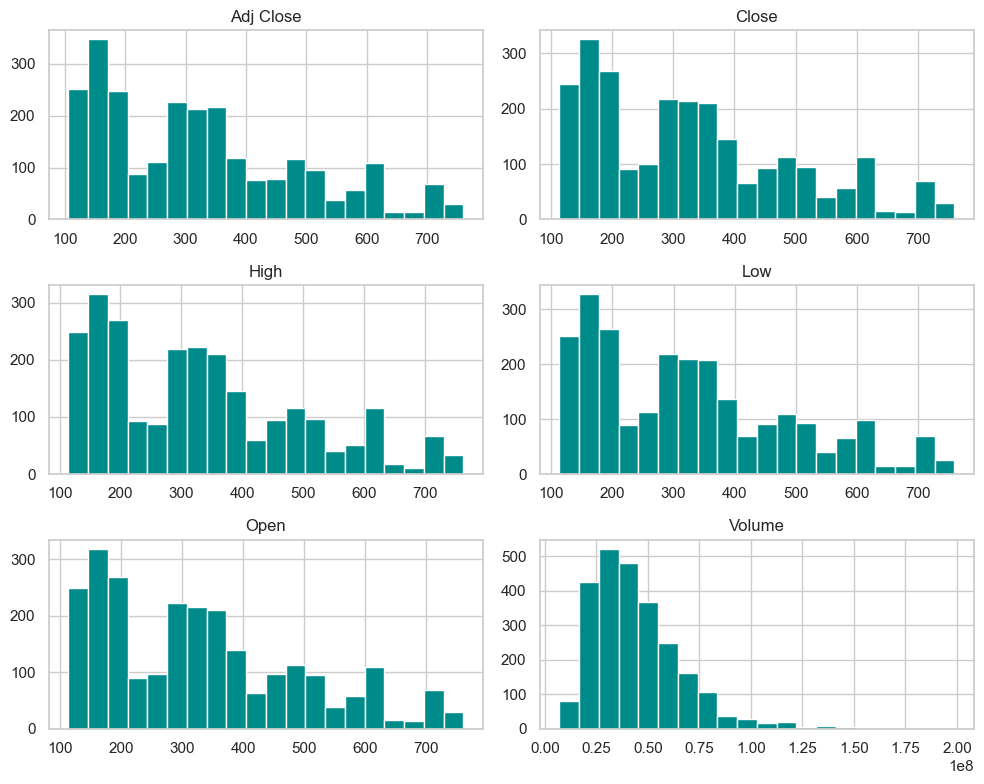

In [10]:
# Univariable Analysis - Numerical Variables.
df_QQQ.hist(figsize=(10,8), bins=20, color="darkcyan")
plt.tight_layout()
plt.show()

***Symmetry***

Based on the descriptive table and histograms:

Adj Close -The varible ranges from 106.20 to 759.65 with a median in 300.35. The graphic shows a Bimodal pattern showing two distinct peaks around 150 and 350, with a long right tail extending towards higuer prices.

Close - The varible shows the last traded price at the end of the tradind day. It ranges from 113.65 to 759. It Has a right-skewed distribution, as evidenced by the long right tail in the histogram.

High - The varible represents the highest price  reached during the trading day (peak).The distribution is right-skewed, however, the graphic demostrated a right tail of the distribution. The variable has ranges from 114.54 to 762.85

Low - This represents the lowest price that QQQ GOT  reached during the trading day. The distribution is right-skewed, the graphic demostrated a right tail of the distribution, The graphic shows a slightly bimodal patern.

Open -  This is the price at wich the addet firt traded when the market opened. The distribution is right-skewed. The range is from 113.76 to 760.52. 

Volumen-  The distribution is right-skewed and it has a unimodal pattern with a long right tail. The range from 7.079300e+06 to 1.986858e+08.


#### 2.2.3 Outliers

To analyse the number of outliers per category, I apply sns.boxplot to get a illustration of a boxplot per each one, in general the data does not have a big number of outliers.

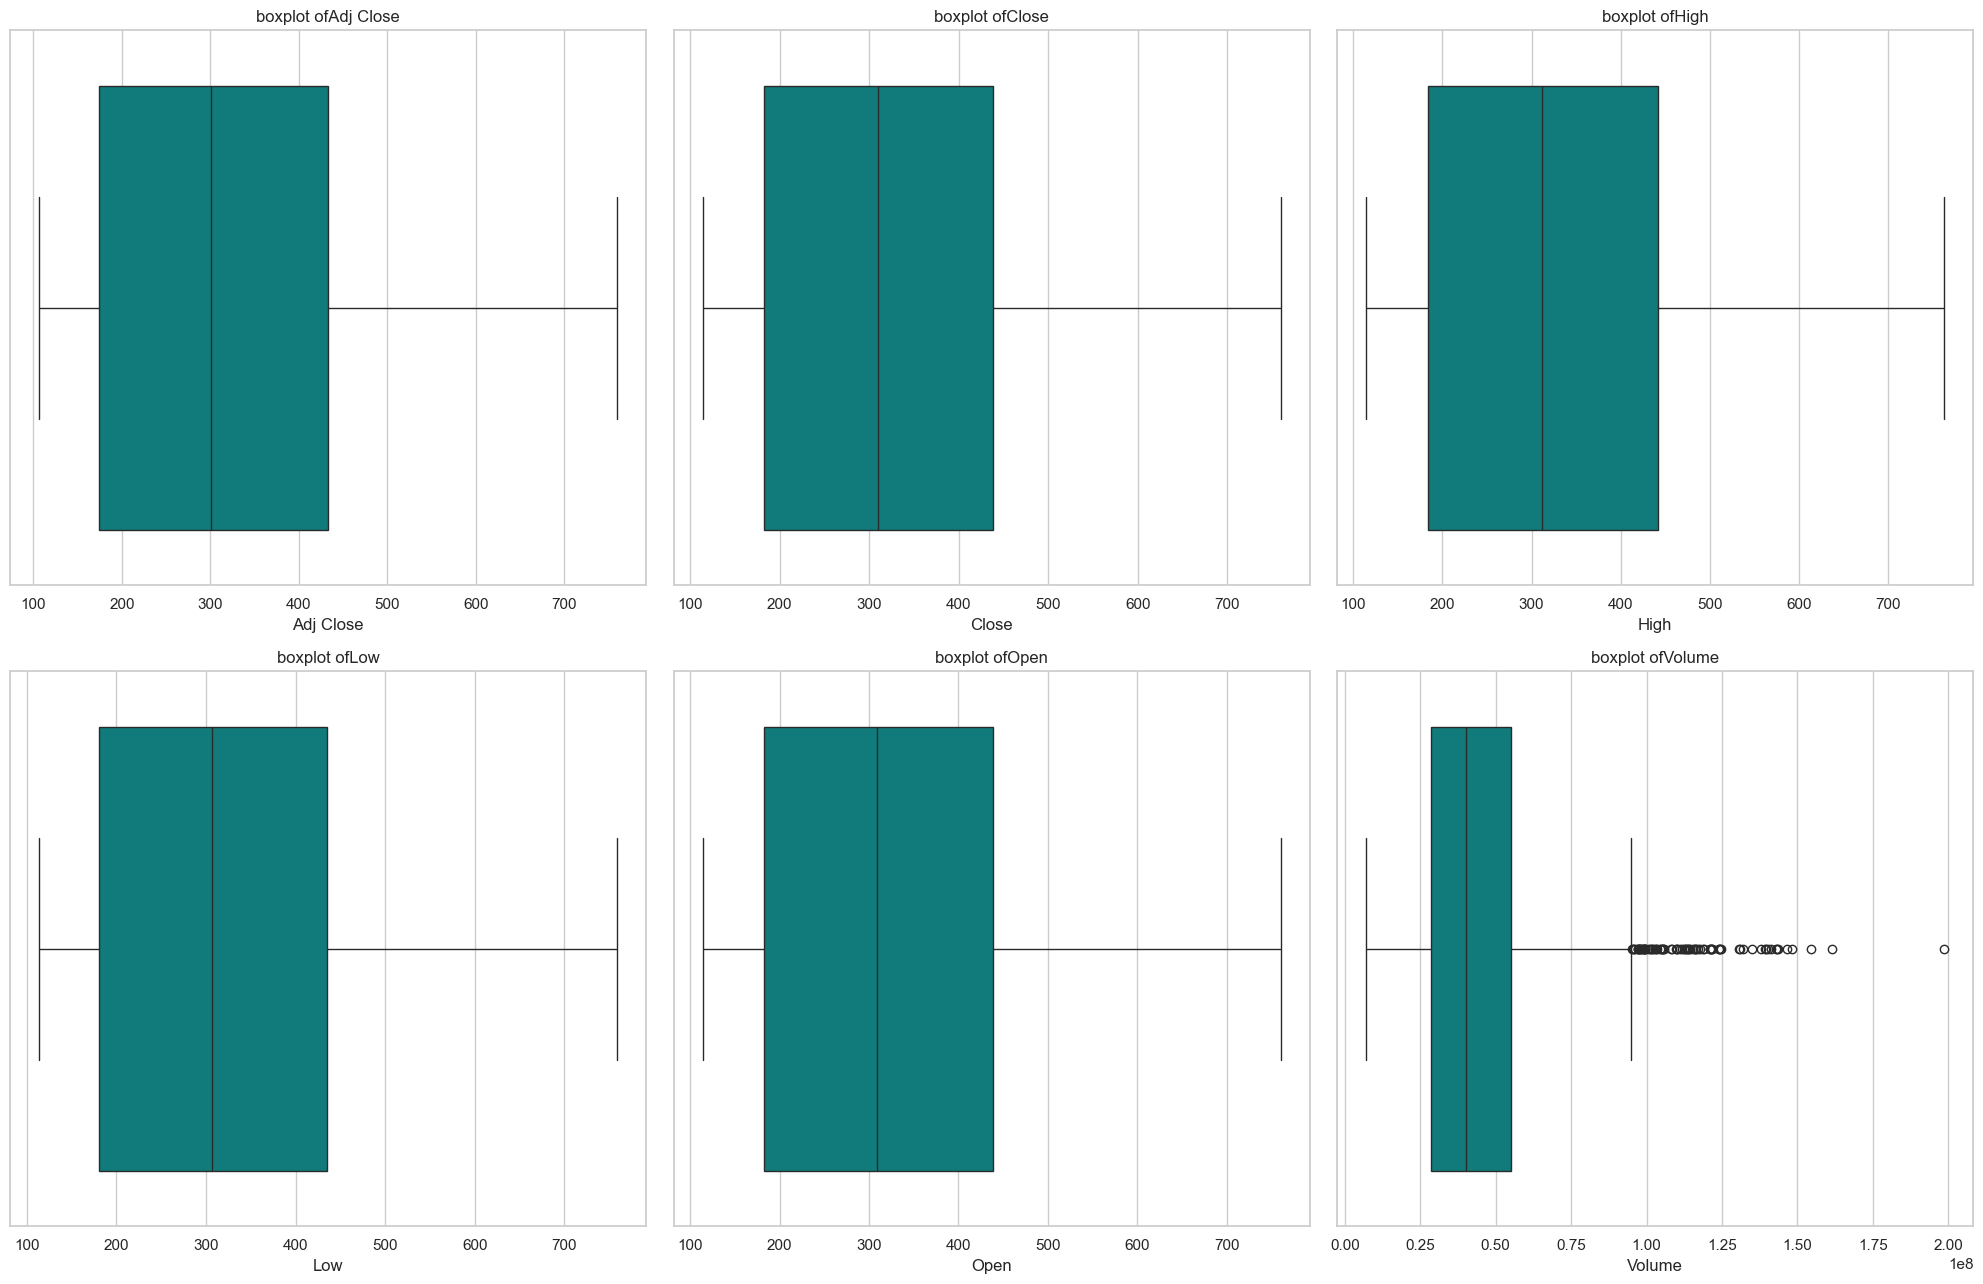

In [11]:
# Boxplots for each variable
Columns_num=['Adj Close', 'Close', 'High', 'Low', 'Open','Volume']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20,13))
axes = axes.flatten()

for i, col in enumerate(Columns_num):
    sns.boxplot(x=df_QQQ[col], ax=axes[i], color='darkcyan')
    axes[i].set_title(f'boxplot of{col}')

for j in range(len(Columns_num), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Based on the Boxplot:

The varaibles Adj Close', 'Close', 'High', 'Low', 'Open','Volume' are not showing outliers, however the variable Volume reveals a significant number of upper outliers, the boxplots shows most trading days have a normal volume. However, there is a long tail of outliers. The extreme volume days are not errors, they are real values and for this project represet the "shock days"usually those are caused by  market panic, news or reports, onthese days the price moves much faster and volatility is vary high. It means this values wont be deleting.

#### 2.2.4 Correlations

To understand how the variables are linked between them and find the statistical relation between two variables I'll apply the correlation   

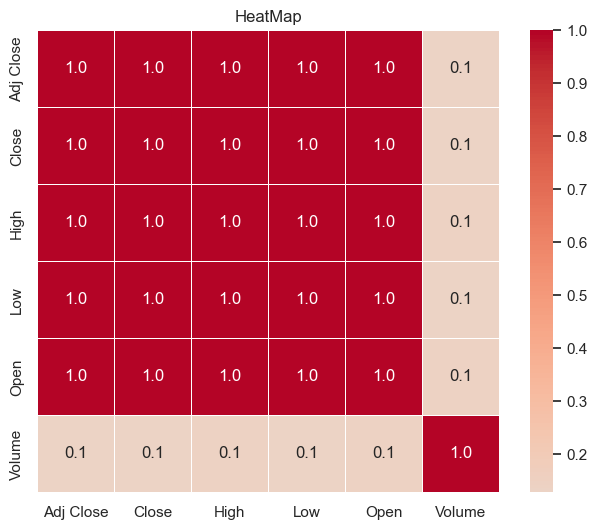

In [12]:
#Applying the correlation graphic
Columns_num=['Adj Close', 'Close', 'High', 'Low', 'Open','Volume']
corr = df_QQQ[Columns_num].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.1f',
           cmap='coolwarm', center=0, square=True,
           linewidths=0.5)
plt.title("HeatMap")
plt.show()

The correlation matrix shows that all price variables ('Adj Close', 'Close', 'High', 'Low', 'Open') are perfectly correlate (1.0). However, Volume has a very low correlation (0.1) with price. It means that trading activity is indipendent of the price level.

#### 2.2.6 Relation between variables

The Volatility is a measure of how much an asset’s price changes over time. Although it is often associated with falling markets, it applies to both upward and downward price movement.(Abu Summaqa, 2026), It means the next graph describe the speed of price movement. 

The formula of daily voltility is a substraction between the highest price of the day and the loest prices

In [13]:
df_QQQ['Volatility']= df_QQQ['High'] - df_QQQ['Low']

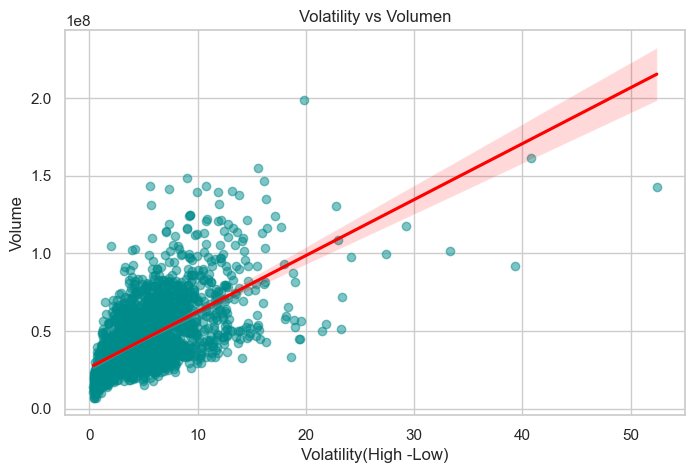

In [14]:
plt.figure(figsize=(8,5))
sns.regplot(x='Volatility', y='Volume', scatter_kws={'alpha':0.5}, color='darkcyan', line_kws={'color':'red'},
          data=df_QQQ)
plt.title("Volatility vs Volumen")
plt.xlabel("Volatility(High -Low)")
plt.ylabel("Volume")
plt.show()

The last scatterplot is showing the trading days in QQQ history, a regression tendency (red line) as the red line is going up, it shows a positive correlation. 

In [15]:
#.describe to Get the statisitical measures of Data set, count, mean, standard desviation minimun  
#and maximun value and the quartiles all of this are the measures of descriptive statistical for each variable
df_QQQ.describe()

,Adj Close,Close,High,Low,Open,Volume,Volatility
count,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2.513000e+03,2513.000000
mean,324.315840,331.412543,333.727055,328.734262,331.346450,4.443782e+07,4.992793
std,165.610147,163.633973,164.617143,162.464315,163.632783,2.198598e+07,3.894413
min,106.206009,113.650002,114.540001,113.449997,113.769997,7.079300e+06,0.369995
25%,174.408707,182.639999,183.809998,181.059998,182.399994,2.849590e+07,2.190002
50%,300.353302,309.250000,311.880005,306.399994,309.029999,4.011360e+07,4.279999
75%,432.523712,438.269989,441.600006,435.109985,438.230011,5.517260e+07,6.670044
max,759.659973,759.659973,762.859985,759.099976,760.520020,1.986858e+08,52.399994


## 3. Data Preparation

### 3.1 Cleaning dataset

#### 3.1.1 Handing dupplicated
To getting the total of duplicates in the data set I apply the .Duplicate() formula. In case that it will be different to 0, I will remove it because this could alter my data and analysis.

In [16]:
# checking Duplicates values
DUP = df_QQQ.duplicated().sum()
DUP

0

#### 3.1.2 Handle missing values

Handling missing values, is one of the most important things to verify because it can be affecting the analysis and models behaviour in consequence the models can learn wrong patterns making a default system behaviour. I'll use  the formule.isnill().sum() to know how many missing values have each category.


In [17]:
#Checking if there is any null value
df_QQQ.isnull().sum()

Date          0
Adj Close     0
Close         0
High          0
Low           0
Open          0
Volume        0
Volatility    0
dtype: int64

There is not null values in the dataset

### 3.2 Feature Engineering

This is one of the most relevant steps before Modeling, as I have a series of prices and they are non-stationary time series checking the mean, variance and correlation i can see they are not constant because the median rise every year moreover the lowest price was 113 USD, and the higuest price was  756 USD,  in conclution, the serie of proces is non stacionary time series and it has trend. It represent a problem because ARIMA demands seasonality. To have a good result with the project it is necesary  applying Feature engineering:

In [18]:
#Getting the information about the table
df_QQQ.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2513 entries, 0 to 2512
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        2513 non-null   object 
 1   Adj Close   2513 non-null   float64
 2   Close       2513 non-null   float64
 3   High        2513 non-null   float64
 4   Low         2513 non-null   float64
 5   Open        2513 non-null   float64
 6   Volume      2513 non-null   int64  
 7   Volatility  2513 non-null   float64
dtypes: float64(6), int64(1), object(1)
memory usage: 157.2+ KB


#### 3.2.1 Log_Return

Log returns are a smart way to measure price changes (Muller, 2023), The mathemathical models works bette with the same scale, this variable allows the model compare the prices between the years or days it compare today's closing prices with yesterday's and allows clustering gropup per behaviour and trend not with years.

Formula: ln(P_t / P_{t-1})

In [19]:
#Convert date to date type
df_QQQ['Date'] = pd.to_datetime(df_QQQ['Date'])
#Sorting the rows from the oldest to the youngest
df_QQQ = df_QQQ.sort_values('Date').reset_index(drop=True)
#applying the formula of log_return
df_QQQ['Log Return'] = np.log(df_QQQ['Adj Close']/ df_QQQ['Adj Close'].shift(1))
#dropping the first raw because it generate nan
df_QQQ = df_QQQ.dropna(subset=['Log Return']).reset_index(drop=True)
print(df_QQQ.shape)
df_QQQ[['Date', 'Adj Close', 'Log Return']].head()

(2512, 9)


,Date,Adj Close,Log Return
0,2016-10-11,109.822533,-0.014362
1,2016-10-12,109.729073,-0.000851
2,2016-10-13,109.336586,-0.003583
3,2016-10-14,109.467400,0.001196
4,2016-10-17,109.168381,-0.002735


#### 3.2.2 Range_pct

The Range_ pct variable it is on of the most important variables in trading it allows to measure how much the ETF's price moved during the day in percentage(%), because naturally two days with the same closing price can be very different.To do the clustering  this variable give the algorthmin a features where it can distinguish  between days that look the same at first glance but they are very differnt of their behavior.

Formula: Range pct= (High - low)/  Close*100

In [20]:
#Applying the formula of range pct and add the variable to the data set 
df_QQQ['Range pct'] = (df_QQQ['High']- df_QQQ['Low'])/ df_QQQ['Close']*100
#Checking the results
print(df_QQQ.shape)
df_QQQ[['High', 'Low', 'Close', 'Range pct']].head()

(2512, 10)


,High,Low,Close,Range pct
0,119.139999,117.000000,117.519997,1.820966
1,117.820000,117.059998,117.419998,0.647251
2,117.320000,115.940002,117.000000,1.179485
3,118.050003,117.070000,117.139999,0.836609
4,117.300003,116.669998,116.820000,0.539295


#### 3.2.3 Log_Volume

Log volume allows the algoritmic normalice the volume to works easier, because it reduce the bias and the assimetry. Usually the Transaction volume in trading is often highly skewed and spans extreme ranges (from thousands to billions). When a logarithm is applied, the distribution becomes more symmetrical and closer to a normal curve (Goyenko et al., 2024) it means that it reduces the outliers and improve the stability of clustering models and series times.

formula: Log_Volume = log10(volume)

In [21]:
#Applying the formula of Log Volume and add the variable to the data set 
df_QQQ['Log Volume'] = np.log10(df_QQQ['Volume'])
#Checking the results
print(df_QQQ.shape)
df_QQQ[['Date', 'Volume','Log Volume']].head()

(2512, 11)


,Date,Volume,Log Volume
0,2016-10-11,27774400,7.443645
1,2016-10-12,14267800,7.154357
2,2016-10-13,22821000,7.358335
3,2016-10-14,21313300,7.328651
4,2016-10-17,14182700,7.151759


#### 3.2.4 Volatility_20

The volatility allows the algorithmin measure how much returns fluctuate over time and higher values indicate a more unstable market(Hayes,2025).It is calculated with the stard deviation  of the returns over 1 month window, exactly 20 days because the stock market has moviments weekly.

formula_20 = Standard Deviation of (Log Return) over the last 20 days.

In [22]:
#Applying the formula of Volatility_20 and add the variable to the data set 
df_QQQ['Volatility_20'] = df_QQQ['Log Return'].rolling(20).std()
#Checking the results
df_QQQ[['Date', 'Log Return','Volatility_20']].head(30)

,Date,Log Return,Volatility_20
0,2016-10-11,-0.014362,NaN
1,2016-10-12,-0.000851,NaN
2,2016-10-13,-0.003583,NaN
3,2016-10-14,0.001196,NaN
4,2016-10-17,-0.002735,NaN
5,2016-10-18,0.008863,NaN
6,2016-10-19,-0.000085,NaN
7,2016-10-20,-0.001188,NaN
8,2016-10-21,0.003731,NaN
9,2016-10-24,0.011947,NaN


The table is showing a NaN  value, because there are not enpugh past data points to calculate the 20 day window 

#### 3.2.5 Volume_Ratio

The Volume Ratio indicator measures the relationship between buying and selling volume in a market over a specified period. (MarketInOut, n.d.). 

Formula=  Positive volume / Volume_MA20. Before applying the Volume_ratio, I should create the variable Volume_MA20, the Moving Average of 20 days) it is because I can not split between 0 and I need a baseline to determine if the daily traidingactivity is normal or abnormal. By creating the Volume_MA20, I can divide the daily Volume by this monthly average.

In [23]:
#Applying the formula of Volatility_MA20 and add the variable to the data set 
df_QQQ['Volume_MA20'] = df_QQQ['Volume'].rolling(20).mean()
#Applying the formula of Volume Ratio and add the variable to the data set 
df_QQQ['Volume_Ratio'] = df_QQQ['Volume']/ df_QQQ['Volume_MA20']
df_QQQ[['Date', 'Volume','Volume_MA20','Volume_Ratio']].head(30)

,Date,Volume,Volume_MA20,Volume_Ratio
0,2016-10-11,27774400,NaN,NaN
1,2016-10-12,14267800,NaN,NaN
2,2016-10-13,22821000,NaN,NaN
3,2016-10-14,21313300,NaN,NaN
4,2016-10-17,14182700,NaN,NaN
5,2016-10-18,19276700,NaN,NaN
6,2016-10-19,13702900,NaN,NaN
7,2016-10-20,18132200,NaN,NaN
8,2016-10-21,15707800,NaN,NaN
9,2016-10-24,19143000,NaN,NaN


In [24]:
#Verifying the df_QQQ
df_QQQ.head(30)

,Date,Adj Close,Close,High,Low,Open,Volume,Volatility,Log Return,Range pct,Log Volume,Volatility_20,Volume_MA20,Volume_Ratio
0,2016-10-11,109.822533,117.519997,119.139999,117.000000,119.120003,27774400,2.139999,-0.014362,1.820966,7.443645,NaN,NaN,NaN
1,2016-10-12,109.729073,117.419998,117.820000,117.059998,117.629997,14267800,0.760002,-0.000851,0.647251,7.154357,NaN,NaN,NaN
2,2016-10-13,109.336586,117.000000,117.320000,115.940002,116.620003,22821000,1.379997,-0.003583,1.179485,7.358335,NaN,NaN,NaN
3,2016-10-14,109.467400,117.139999,118.050003,117.070000,117.580002,21313300,0.980003,0.001196,0.836609,7.328651,NaN,NaN,NaN
4,2016-10-17,109.168381,116.820000,117.300003,116.669998,117.040001,14182700,0.630005,-0.002735,0.539295,7.151759,NaN,NaN,NaN
5,2016-10-18,110.140266,117.860001,118.410004,117.800003,118.209999,19276700,0.610001,0.008863,0.517564,7.285033,NaN,NaN,NaN
6,2016-10-19,110.130905,117.849998,118.019997,117.639999,117.769997,13702900,0.379997,-0.000085,0.322441,7.136812,NaN,NaN,NaN
7,2016-10-20,110.000099,117.709999,117.970001,117.029999,117.730003,18132200,0.940002,-0.001188,0.798575,7.258451,NaN,NaN,NaN
8,2016-10-21,110.411247,118.150002,118.220001,117.410004,117.800003,15707800,0.809998,0.003731,0.685567,7.196115,NaN,NaN,NaN
9,2016-10-24,111.738258,119.570000,119.650002,118.889999,118.910004,19143000,0.760002,0.011947,0.635613,7.282010,NaN,NaN,NaN


In [25]:
#Checking NULL values df_QQQ
df_QQQ.isnull().sum()

Date              0
Adj Close         0
Close             0
High              0
Low               0
Open              0
Volume            0
Volatility        0
Log Return        0
Range pct         0
Log Volume        0
Volatility_20    19
Volume_MA20      19
Volume_Ratio     19
dtype: int64

The dataset it is showing 19 null values, To handle the null values I going to delete the values, it does not represent more than 13% of the data, also we have  enough data  to work without this 19 values. 

In [26]:
#Dropping the Null values
df_QQQ=df_QQQ.dropna().reset_index(drop=True)
df_QQQ.isnull().sum()

Date             0
Adj Close        0
Close            0
High             0
Low              0
Open             0
Volume           0
Volatility       0
Log Return       0
Range pct        0
Log Volume       0
Volatility_20    0
Volume_MA20      0
Volume_Ratio     0
dtype: int64

#### 3.2.6 Outliers

To analyse the number of outliers per the news variables, I apply sns.boxplot to get a illustration of a boxplot per each one.

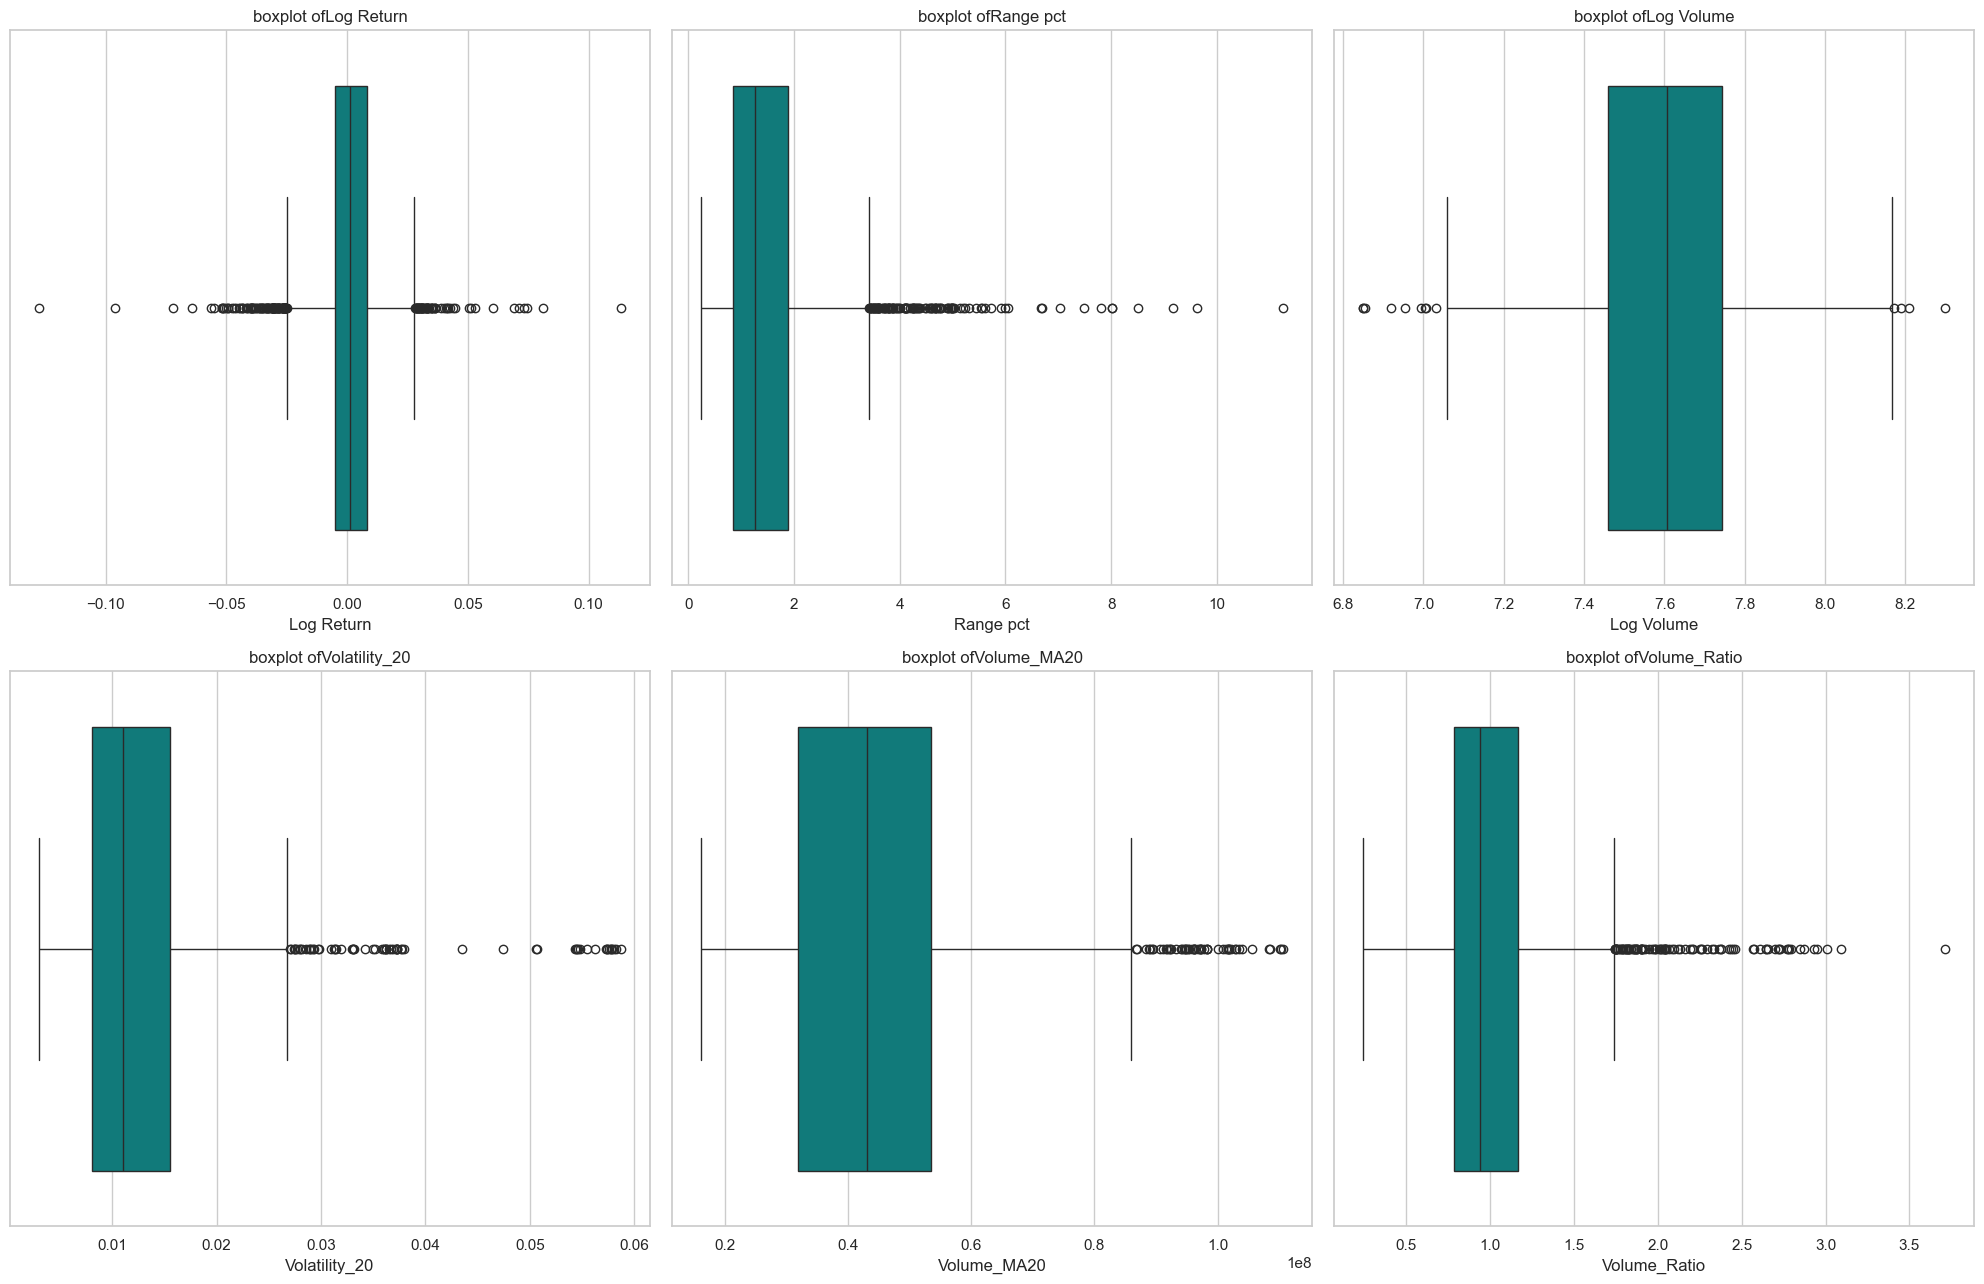

In [27]:
# Boxplots for each variable
Columns_num=['Log Return', 'Range pct', 'Log Volume',
           'Volatility_20','Volume_MA20','Volume_Ratio']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20,13))
axes = axes.flatten()

for i, col in enumerate(Columns_num):
    sns.boxplot(x=df_QQQ[col], ax=axes[i], color='darkcyan')
    axes[i].set_title(f'boxplot of{col}')

for j in range(len(Columns_num), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

- **Log Return & Range PCT**: Most days show returns close to 0 and a daily range  of 1.5%. How ever price movements up to +- 10%.
- **Log Volume** showa  outliers on the left side die to the logarithmic transformation that was applied, it compresses a large numbers to low volume days. 
- **Volatility_20:** The normal 20 day volatility range between 1 and 2% The outliers show periods of high volatility representing market stress.
- **Volume_MA20**: The ouliers represnet periods of high market activity. They are related with market stess, financial bubbles or crisis.
- **Volume_Ratio:** The median is exactly 1, meaning a normal day trades at it monthly average. The outliers on the right side represent days where volume was more than double the average. these are the shock days.



### 3.4 Scaling
It is  necessary to apply the standardization of numerical variables because each has its own scale, to choose what technique is the best option to scale the data set : 1. Min-max Normalization: This type is used when we know the lower and upper limits and these are fixed. In this case, it is not the most appropriate technique because after log-transformation the influence of outliers is reduced. 2. Standardization: this technique works best when data is approximately normal, after the log-transformation is approximaterly normal.

In [28]:
from sklearn.preprocessing import RobustScaler

In [29]:
#features to scalling
features =['Log Return', 'Range pct', 'Log Volume',
           'Volatility_20','Volume_MA20','Volume_Ratio']
#Applying scaler
scaler = RobustScaler()
df_QQQ[['Log Return_scaled',
          'Range pct_scaled',
          'Log Volume_scaled',
         'Volatility_20_scaled',
         'Volume_MA20_scaled',
         'Volume_Ratio_scaled']] = scaler.fit_transform(df_QQQ[features])
#verifying the result
print()
print("scaled features:")
print(df_QQQ[['Log Return_scaled',
          'Range pct_scaled',
          'Log Volume_scaled',
         'Volatility_20_scaled',
         'Volume_MA20_scaled',
         'Volume_Ratio_scaled']].describe().round(2))


scaled features:
       Log Return_scaled  Range pct_scaled  Log Volume_scaled  \
count            2493.00           2493.00            2493.00   
mean               -0.04              0.25              -0.01   
std                 1.08              0.98               0.72   
min                -9.75             -0.99              -2.66   
25%                -0.49             -0.40              -0.52   
50%                 0.00              0.00               0.00   
75%                 0.51              0.60               0.48   
max                 8.47              9.71               2.44   

       Volatility_20_scaled  Volume_MA20_scaled  Volume_Ratio_scaled  
count               2493.00             2493.00              2493.00  
mean                   0.21                0.07                 0.19  
std                    0.93                0.76                 0.94  
min                   -1.07               -1.24                -1.82  
25%                   -0.39              

In [30]:
#Checking the scaled variables
df_scaled=df_QQQ[['Log Return_scaled','Range pct_scaled','Log Volume_scaled',
                  'Volatility_20_scaled','Volume_Ratio_scaled']]
#Checking the values
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2493 entries, 0 to 2492
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Log Return_scaled     2493 non-null   float64
 1   Range pct_scaled      2493 non-null   float64
 2   Log Volume_scaled     2493 non-null   float64
 3   Volatility_20_scaled  2493 non-null   float64
 4   Volume_Ratio_scaled   2493 non-null   float64
dtypes: float64(5)
memory usage: 97.5 KB


The table shows the descriptive statistics of the variables after applying a scaling process. This is a crucial step before running any clustering algorithm. The original variables had different units ( Volume in millons, volatility in decimals). 
After scaling, all variables are measured from the mean that is normalized to 0 to the standar deviation that is approximately 1. 


### 3.4.1 EDA Scaled variables

After understanding the dtype of each feature it is important to examine the characteristic of the data, as distribution, unusual values and potential issues. For this purpose, I will analyse the variables numericals doing a univariable analysis and bivariate analysis.

##### Univariable Analysis - Histogram Numerical Variables scaled.

I evaluate each variable; this analysis is conducted to understand the distribution of each variable and their behavior.To analyse the numerical variables('Log Return_scaled','Range pct_scaled','Log Volume_scaled','Volatility_20_scaled', 'Volume_Ratio_scaled'), I use histogram to see the centre, symmetric shaped and spread of dataset I used. Hist to get the information:

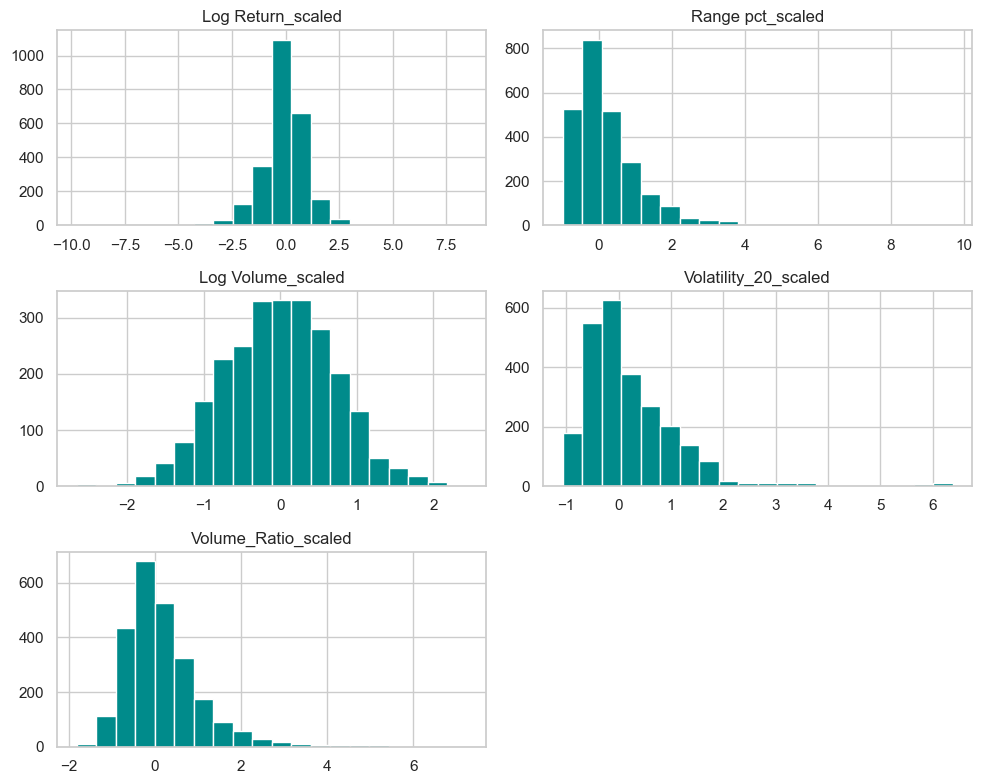

In [31]:
df_scaled.hist(figsize=(10,8), bins=20, color="darkcyan")
plt.tight_layout()
plt.show()

Based on the descriptive table and histograms, Overall all variables are now cetered at 0.0.

- **Log Return_scaled** The varible is showing a near normal distribution, with most days claustering between -1 and 1. The extreme tails represent crash or crisis days

- **Range pct_scaled and Volatility_20**: Both exhibit a strong right-skew (long right tail). While most days have low movement, the long tails represent days or periods of severe market stress.

- **Log Volume_scaled** the histogram shows a nearly symmetrical, bell-shaped distribution centered at 0.

- **Volume_Ratio_scaled**  This is the most critical for outlier detection. Most of the distribution is concentrated at 0 , but the extreme right tail extends beyond 5.


#### Boxplots scaled variables

To analyse the number of outliers per the news variables, I apply sns.boxplot to get a illustration of a boxplot per each one.

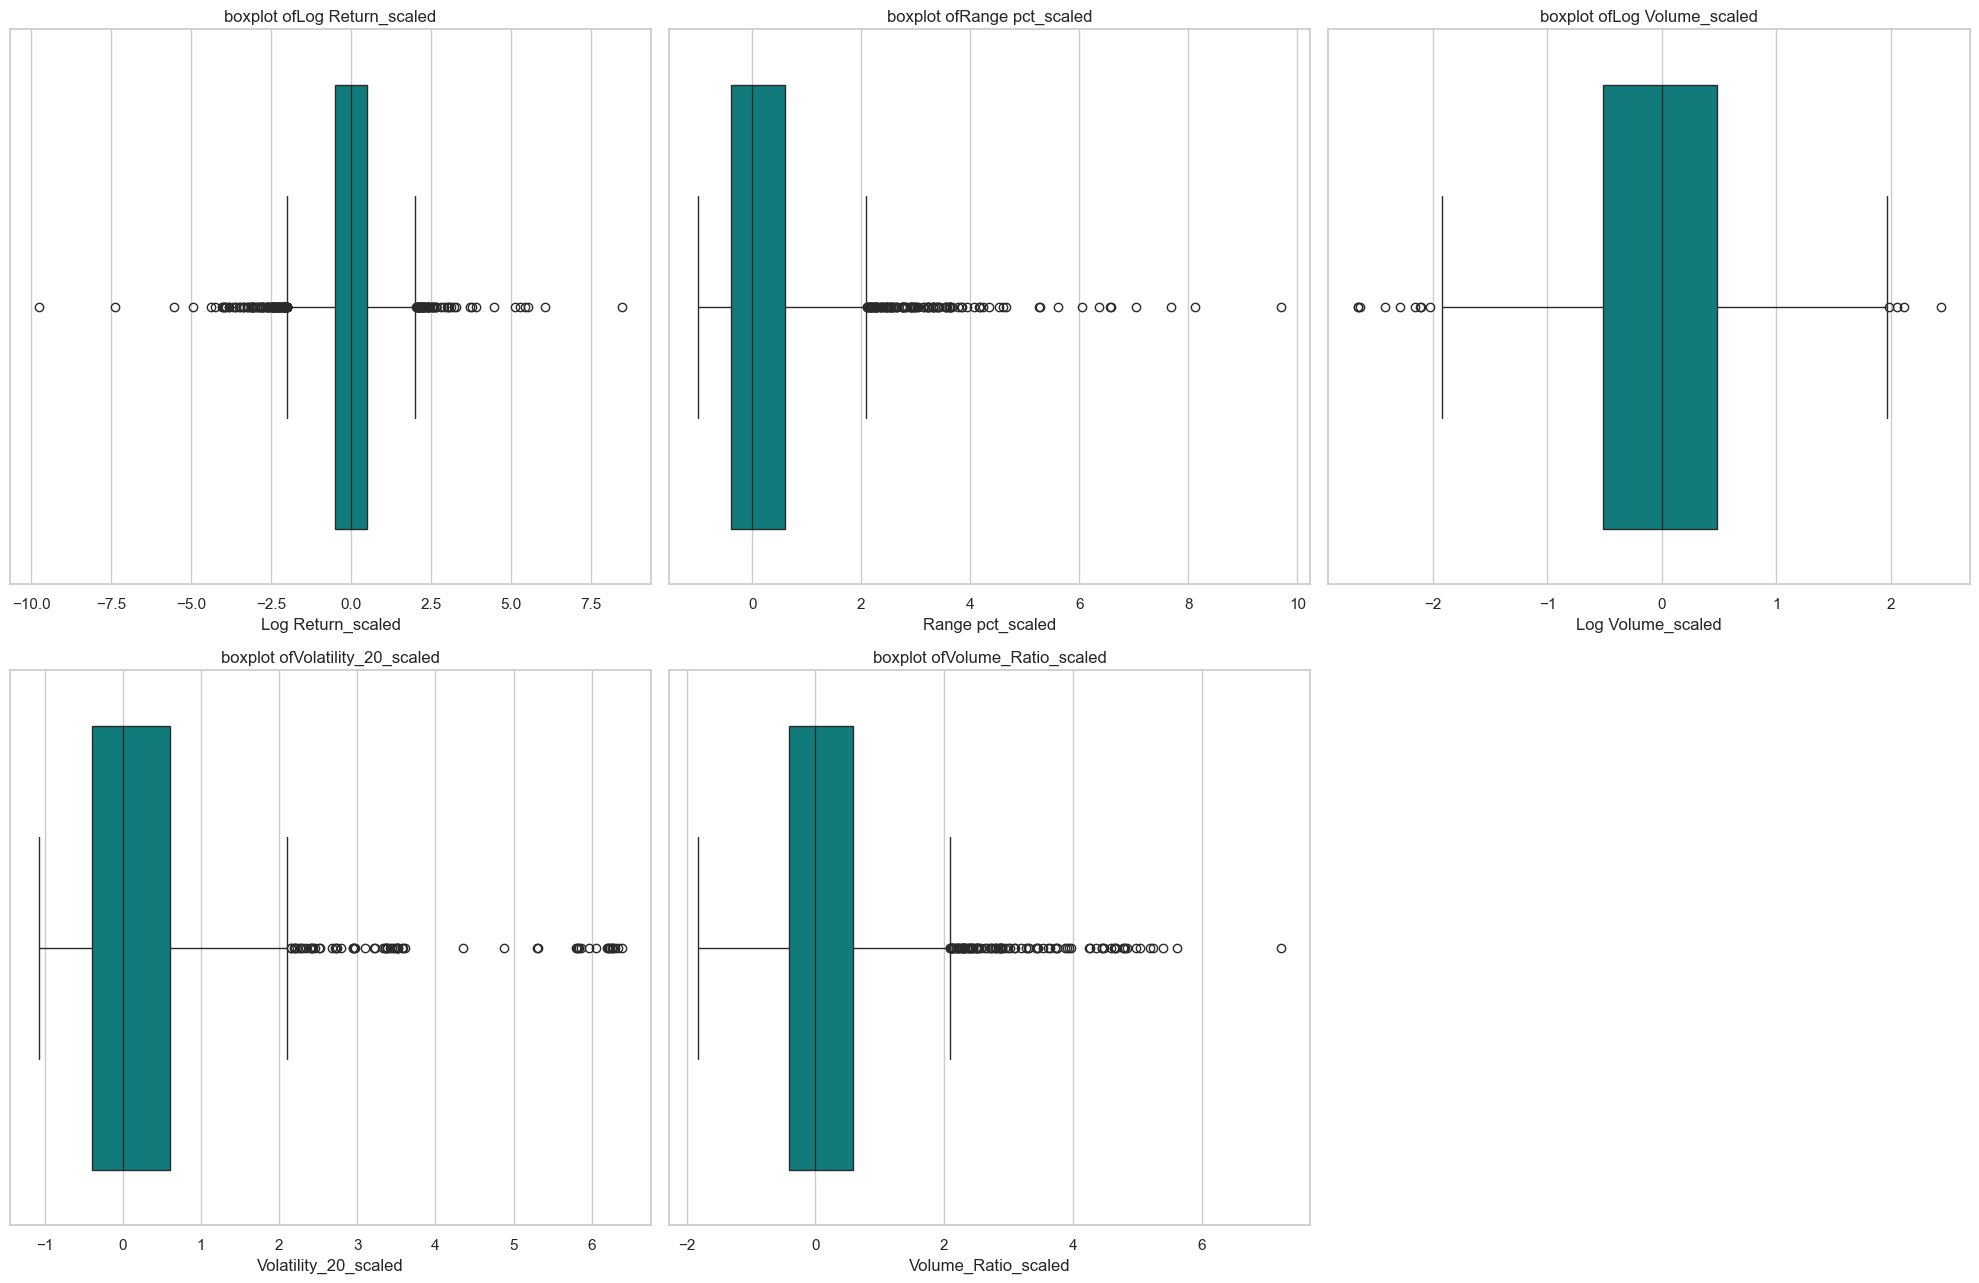

In [32]:
# Boxplots for each variable
Columns_num_scaled=['Log Return_scaled','Range pct_scaled','Log Volume_scaled',
                    'Volatility_20_scaled','Volume_Ratio_scaled']
#Plotting the boxplot for scaled variables
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20,13))
axes = axes.flatten()

for i, col in enumerate(Columns_num_scaled):
    sns.boxplot(x=df_scaled[col], ax=axes[i], color='darkcyan')
    axes[i].set_title(f'boxplot of{col}')

for j in range(len(Columns_num_scaled), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

 The figure displays the boxplots after the standardization process. All variables are now centerd at 0.
 
- **Log Return_scaled** The core data is tightly around 0. However, the outliers extend as far as -9.5 and =8.5. 

- **Range pct_scaled and Volatility_20**: Both show a concentration of data around 0, but posses a long tail of outliers on the right. The outliers respresnt a petiods o high market volatility.

- **Log Volume_scaled** Shows a distribution centered around 0. While the box represents a normal trading activity, the outliers revels the extremes of market particitaption.

- **Volume_Ratio_scaled**  The median is at0.The most critical feature here is the long risght tail of outliers. These represent "shock days" where trading colume was higuer that the recent average


#### Correlations

To understand how the variables are linked between them and find the statistical relation between two variables I'll apply the correlation   

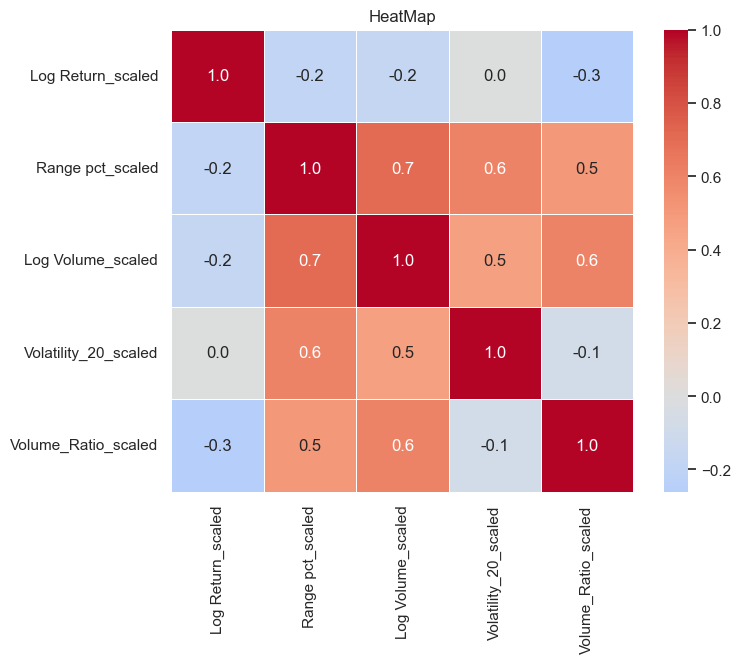

In [33]:
#Applying the correlation for df_scaled
corr = df_scaled.corr()
#Plotting the correlation 
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.1f',
           cmap='coolwarm', center=0, square=True,
           linewidths=0.5)
plt.title("HeatMap")
plt.show()

The correlation matrix shows that scaled variables ('Log Return_scaled','Range pct_scaled','Log Volume_scaled',
'Volatility_20_scaled','Volume_Ratio_scaled'). The most notable correlation is between Range pct and Log volume (r=0.7), a moderate positive relation, also (Range pct and volatility_20) and (Range pct and volatility_20)  have a moderate positive relation r=0.6. It means these variables should be analyzed together.

### 3.5 PCA

The clustering is an unsepervised learning problem where no predifined labels exist. To visualize and optimize the data, I apply PCA to 5 features of the model

In [34]:
#Import library
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [35]:
#Applying pca variance 0,98 for the df_scaled
X = df_scaled
pca_1 = PCA(n_components=0.98)
X_pca = pca_1.fit_transform(X)
print("Components sel", pca_1.n_components_)
print("Cumulative Variance:", sum(pca_1.explained_variance_ratio_) )

Components sel 5
Cumulative Variance: 0.9999999999999998


The PCA with requesting of 98% of the original variance got a result of 5 components selected. This means that all the original variables hold relevant and non-redundant information.

In [36]:
#Applying pca 2d to do a graph 
pca_2 = PCA(n_components=2)
X_pca2 = pca_2.fit_transform(X)
print(pca_2.explained_variance_ratio_.sum())

0.7406149593333213


To visualize the data in a 2D space, I requested PCA to reduce the data to only 2 components. These 2 dimensions retain 74% of the total information.

While the algorithm needs all 5 variables for 1005 accurate clustering model  the first 2 PCA components  contains 74% of the information this will be used to create  the visualization.

## 4. Modeling Clustering 

### 4.1 Selection of the algorithm

This projects is segmenting trading days according to their behavior, It does not have labels, which is why the project should use unsupervised learning. To choose the correct model, it is important to perfom an EDA analysis: 

1. After getting the Boxplot graphics I identifief strong Outliers (Log Return, Range pct, Volatility_20 and volume ratio. those are real values, wich is why I did not delete them.
2. the variables Range pct, volatility_20 and volume Ratio present a right-skewed distribution.
3. The PCA Contains the 5 components,  it means that there is no significant reduction in the dimensionality. 

The algorithms that was selected to do the clustering are: K means and fuzzyC


### 4.2 K-Means 

K-means clustering is a type of unsupervised learning, which is used when you have unlabeled data (i.e., data without defined categories or groups). The goal of this algorithm is to find groups in the data, with the number of groups represented by the variable K. The algorithm works iteratively to assign each data point to one of K groups based on the features that are provided (Trevino, 2025). To do the Kmeans the parameter to use is:
n_clusters =3, I'll use kmeans 3 because we have the data contains days where the price increases, price decreases and calm?quiet days.
n_init= run algorithm 10 times with different centroid seeds

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [38]:
# Load 5 columns scaled of the QQQ data values
x = df_scaled[['Log Return_scaled','Range pct_scaled', 'Log Volume_scaled',
               'Volatility_20_scaled','Volume_Ratio_scaled']].values
print(x)

[[ 1.67273498 -0.2491241  -0.63590804 -0.34574791  0.70115378]
 [ 0.38961373  0.16795343 -1.01292256 -0.40385063  0.05183512]
 [ 0.24515287  0.6243481   0.84845578 -0.39465357  5.04151858]
 ...
 [ 0.24246287 -0.74560034 -0.64037451 -0.17398601 -0.37925738]
 [-0.29509917 -0.38637516 -0.70187133 -0.17525691 -0.45709297]
 [-1.12251213  0.58747112  0.31976228 -0.14532234  1.33565471]]


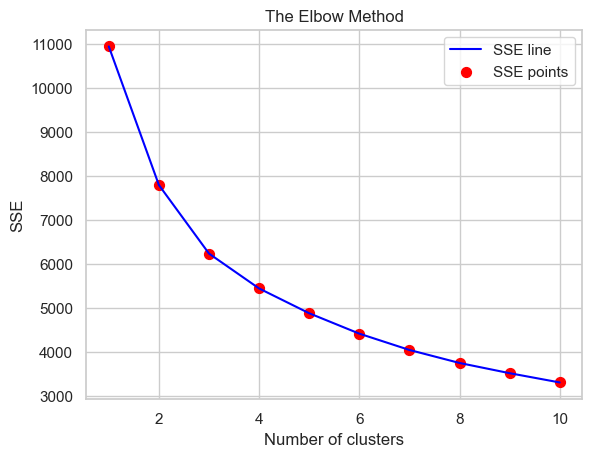

In [39]:
# Finding the optimum number of clusters for k-means classification
sse = []   # Declare an array for the storage of values for Sum of Squares (SSE) Errors

# Set the loop from the minimum and maximum values
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 38)  # Initialise an object kmeans by calling 
                                                                                     # an object KMeans()
    kmeans.fit(x)                                                                    # Training the model by calling fit() method
    sse.append(kmeans.inertia_)                                                      # Store kmeans.inertia_ in the array sse

# Plotting the results onto a line graph with points in a different color
plt.plot(range(1, 11), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 11), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')

plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')  # sum of squares errors
plt.legend()
plt.show()

After applying the Elbow Method, I select k=3 as the optimal number of clusters. The graph shows a sharp decrease from k=1 to k=3. After k=3, the curve begins to flatten significantly. Choosing 3 clusters I have three distinct market regimes of the QQQ.

In [40]:
# Applying KMeans to the dataset/ Creating the kmeans classifier
# 3 clusters
kmeans = KMeans(n_clusters = 3, max_iter = 300, n_init = 10, random_state = 38)
#Fitting Kmeans
y_kmeans = kmeans.fit_predict(x)
#Applying centroids with pca to get the graph
centroids_pca = pca_2.transform(kmeans.cluster_centers_)

In [41]:
# Loop through cluster numbers from 2 to 10
for n_clusters in range(2, 10):
    km_tmp = KMeans(n_clusters = n_clusters, n_init=10, random_state = 42)
    labels_tmp = km_tmp.fit_predict(x)                                # Fit and predict cluster labels
    score = silhouette_score(x, labels_tmp)
    print(f"Silhouette Score (n = {n_clusters}): {score:.4f}")
sil_score = silhouette_score(x, y_kmeans)
# Display the silhouette score values
print(f'Silhouette Score(n = 3): {silhouette_score(x, y_kmeans)}')

Silhouette Score (n = 2): 0.3986
Silhouette Score (n = 3): 0.3611
Silhouette Score (n = 4): 0.2699
Silhouette Score (n = 5): 0.2774
Silhouette Score (n = 6): 0.2655
Silhouette Score (n = 7): 0.2159
Silhouette Score (n = 8): 0.2192
Silhouette Score (n = 9): 0.2193
Silhouette Score(n = 3): 0.3611414718175844


To validate the clustering model and ensrue the quality of the groups, we calculated the Silhouette Score. This metric measures  how well- seperated the clusetes are. According with the literature of financial segmentation n=3 is the optimal choice for financial segmentation (Zhang et al., 2026) after getting the score of 0.36 it reamins positive and robust for financial data (Normal, Trend and shock regimes).

In [42]:
# Display the David Bouldin score valudation
db_score = davies_bouldin_score(x, y_kmeans)
print(f'Davies_bouldin_score(k = 3): {db_score:.4f}')

Davies_bouldin_score(k = 3): 1.2118


To validate Score Validation, I calculated the Davies-Bouldin Score for k=3. The model is showing a score of 1.2. According with the financial literature, a score close to 1.0  (Zhang, 2026)  is considered a good result, it means that the model differentiated the market regimes sucesfully (Normal, Trend, and shock) 

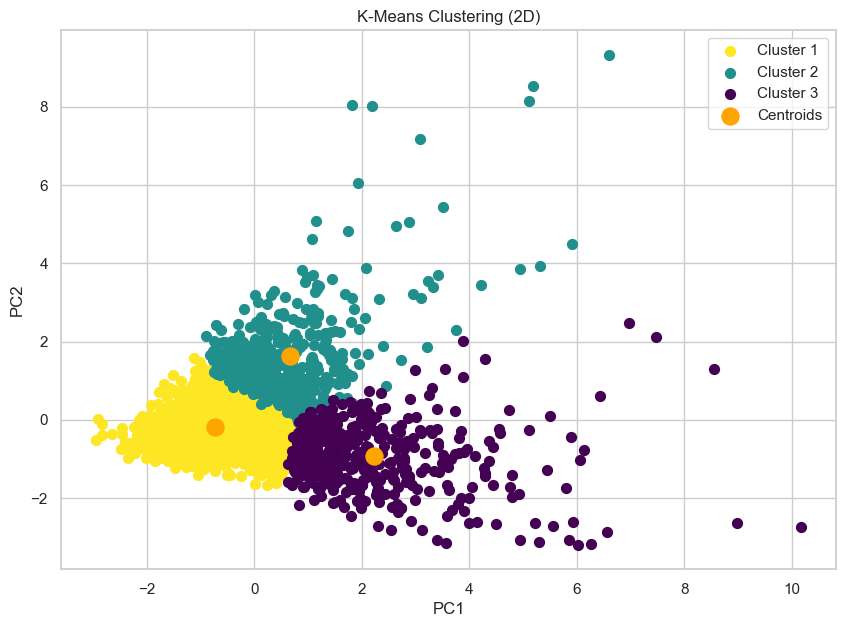

In [43]:
plt.figure(figsize=(10,7))

# Visualising the clusters using scatter() method
plt.scatter(X_pca2[y_kmeans == 0, 0], X_pca2[y_kmeans == 0, 1], s = 50, c = '#FDE725', label = 'Cluster 1')
plt.scatter(X_pca2[y_kmeans == 1, 0], X_pca2[y_kmeans == 1, 1], s = 50, c = '#21908D', label = 'Cluster 2')
plt.scatter(X_pca2[y_kmeans == 2, 0], X_pca2[y_kmeans == 2, 1], s = 50, c = '#440154', label = 'Cluster 3')

# Plotting the centroids of the clusters
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], s = 150, c = 'orange', 
            label = 'Centroids')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-Means Clustering (2D)')
plt.legend(loc='best')
plt.show()

# A legend is an area describing the elements of the graph. In the matplotlib library, there's a function called legend()  

The graph is showing the formation of 3 clustering of distinct market with their respective centroids(orange dots):
- Cluster 1 (Yellow -Normal): Represents the vast majority of trading days.
- Cluster 2 (Teal- panic moment High volatility ): this cluster contains days with high price ranges and high20 day volatility.
- Cluster 3 (Purple-Extreme volume ): this cluster means the  abnormal trading volumen. the far points represnt days  of crisis or stock moments.
- Orange dot: Centroids.

### 4.3 Fuzzy C

#### Fuzzy CMeans Clustering

Fuzzy C Means is a soft clustering technique in which every data point is assigned a cluster along with the probability of it being in the cluster. (Aditi V, 2024)

In [44]:
import numpy as np
import skfuzzy as fuzz

# Select five features for clustering
x = df_scaled[['Log Return_scaled','Range pct_scaled', 'Log Volume_scaled',
               'Volatility_20_scaled','Volume_Ratio_scaled']].values


In [45]:
# Transpose the data matrix so that each row represents a feature and each column represents a data point. 
# The skfuzzy cmeans() function expects input in this format.

x_fcm = x.T

# Declare the number of clusters
n_clusters = 3

# Initilise the model object
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(x_fcm, c = n_clusters, m = 2, error = 0.005,
                                                 maxiter = 1000, init = None, seed = 42)

# pick highest 
fcm_labels = np.argmax(u, axis=0)
sil_fcm = silhouette_score(x, fcm_labels)
db_fcm = davies_bouldin_score(x, fcm_labels)
#printting the score 
print(f" Silhouette Score: {sil_fcm:.4f}")
print(f" davies_bouldin Score: {db_fcm:.4f}")
print(f" FPC (Fuzzy Partition Coefficient): {fpc:.4f}")

 Silhouette Score: 0.2715
 davies_bouldin Score: 1.3504
 FPC (Fuzzy Partition Coefficient): 0.5136


Fuzzy C algorithm was applied to segment the traiding days into 3 market regimes. It is showing a score of  0.27 for Silhouette test, it means a positive scores indicating that the clusters are dostinc and well formed. Secondly,the Davies-Bouldin score: is 1.3504 this confirms that the 3 clousterings are distinct each other. The Fuzzy Partition coeddient has a value of 0.51 indicates a balanced partition.   

In [46]:
centroids_fcm = pca_2.transform(cntr)

<Figure size 1200x500 with 0 Axes>

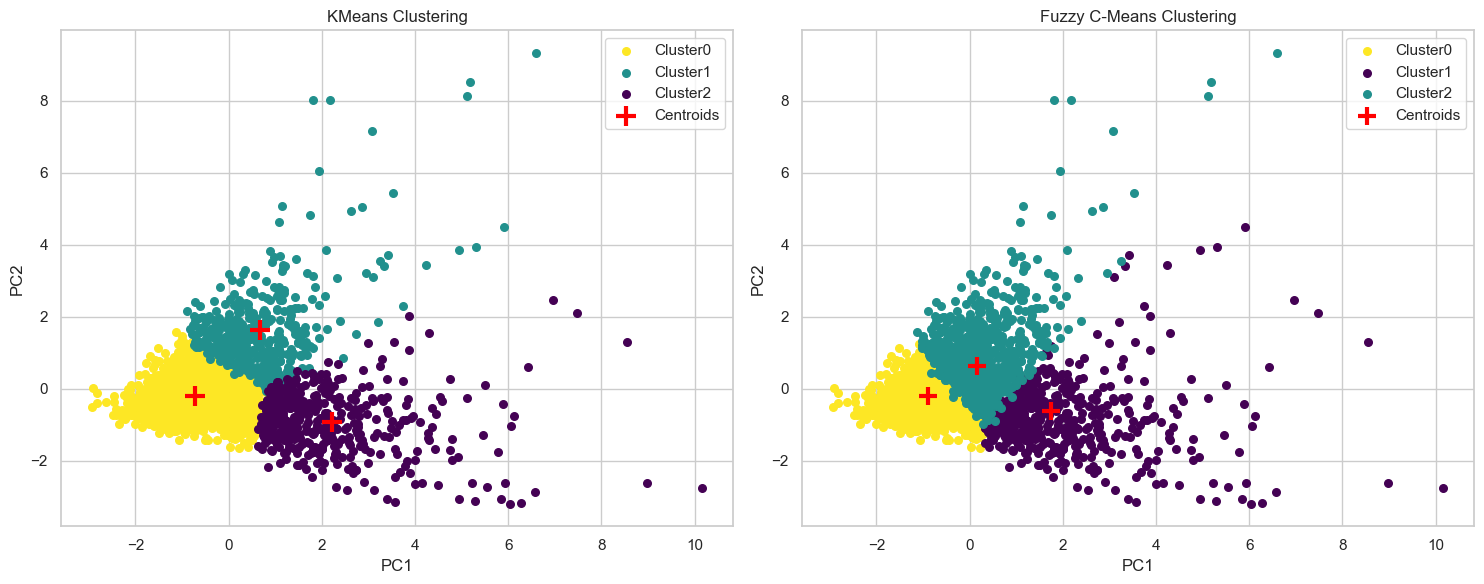

In [47]:
import matplotlib.pyplot as plt

# Plot KMeans results
plt.figure(figsize=(12, 5))
colors =['#FDE725', '#21908D', '#440154']

trad_fuzzy ={0:0,
            1:2,
            2:1
            }
fig,axes = plt.subplots(1,2, figsize=(15,6))

#K-means graph

for i in range(3):
    axes[0].scatter(X_pca2[y_kmeans == i,0], X_pca2[y_kmeans==i, 1],
                    c=colors[i], s=30, label= f'Cluster{i}')
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1],c="red", marker="+", s=200, 
            linewidths=3, label="Centroids")
axes[0].set_title("KMeans Clustering")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()

# Plot FCM results

for i in range (3):
    color_fuzzy = colors[trad_fuzzy[i]]
    axes[1].scatter(X_pca2[fcm_labels ==i, 0], X_pca2[fcm_labels== i, 1], 
                    c=color_fuzzy, s=30, label=f'Cluster{i}')

centroids_fuzzy = pca_2.transform(cntr)
axes[1].scatter(centroids_fuzzy[:,0], centroids_fuzzy[:, 1], c='red', marker="+", s=150, 
            linewidths=3, label="Centroids")
axes[1].set_title("Fuzzy C-Means Clustering")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend()

plt.tight_layout()
plt.show()

The figure compares the clustering results of both algorithms using a standardizedcolor palette (Yellow = Normal behaviour, Teal = High Volatility/panic, Purpuple= Volume shock).

- Kmeans(Left): It creates stricts groups. The purple group clearly shows the days with extreme volume.
- Fuzzy C-Means (Right): It creates more flexible groups. the Yellow group is much bigger and there is much purple points.

Kmeans gives clear and more separate groups. Fuzzy shows market is not alway black or withe some days can share beahvior from different groups

#### Plot overlapped points on both clusters

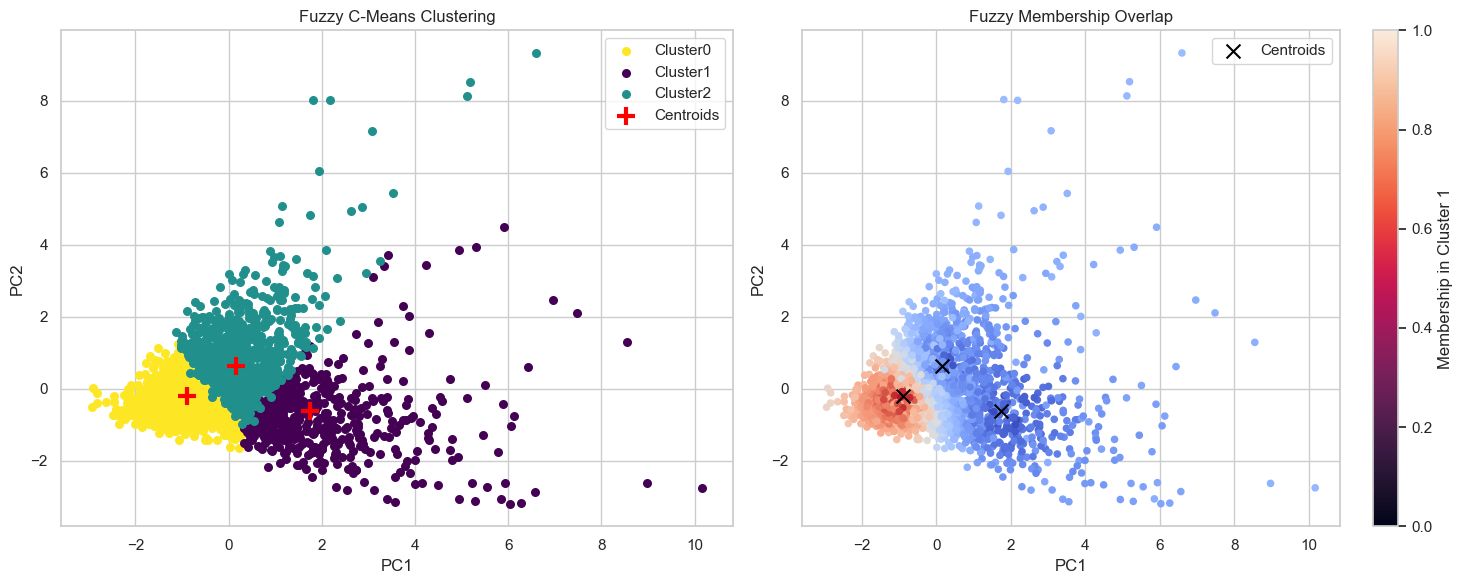

In [48]:
colors =['#FDE725', '#21908D', '#440154']

trad_fuzzy ={0:0,
            1:2,
            2:1
            }
fig, axes = plt.subplots(1,2, figsize=(15,6))

# Subplot 1: Hard assignment (like KMeans)

for i in range (3):
    color_fuzzy = colors[trad_fuzzy[i]]
    axes[0].scatter(X_pca2[fcm_labels ==i, 0], X_pca2[fcm_labels== i, 1], 
                    c=color_fuzzy, s=30, label=f'Cluster{i}')

centroids_fuzzy = pca_2.transform(cntr)
axes[0].scatter(centroids_fuzzy[:,0], centroids_fuzzy[:, 1], c='red', marker="+", s=150, 
            linewidths=3, label="Centroids")
axes[0].set_title("Fuzzy C-Means Clustering")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()

# Subplot 2: Membership strength (shows overlap)

scatter= axes[1].scatter(X_pca2[:, 0], X_pca2[:, 1], c = u[0], cmap = "coolwarm", s = 20)
plt.scatter(centroids_fcm[:, 0], centroids_fcm[:, 1], c = "black", marker = "x", s = 100, label = "Centroids")
axes[1].set_title("Fuzzy Membership Overlap")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
cbar = plt.colorbar()
cbar.set_label("Membership in Cluster 1")
axes[1].legend()

plt.tight_layout()
plt.show()

This figure shows two different views of Fuzzy C- means, the left graph gives a strict classification of each day, while the right graph shows the probability of each day beloging to the central cluster.

In [49]:
import numpy as np

# Threshold on max membership
threshold = 0.6
max_memberships = np.max(u, axis=0)
overlap_mask = max_memberships <= threshold

# Identify overlapped points by either method
overlap_points = X_pca2[overlap_mask]

print(f"Overlap (max membership ≤ {threshold}): {len(overlap_points)} points")

# Example: print a few overlapped points with their memberships
for i, (point, mem) in enumerate(zip(X_pca2[overlap_mask], u.T[overlap_mask])):
    if i < 10:
        print(f"Point {point} -> memberships {mem}")


Overlap (max membership ≤ 0.6): 1077 points
Point [-1.1079617  0.6737   ] -> memberships [0.45725861 0.1254565  0.41728489]
Point [ 2.43105356 -1.38271669] -> memberships [0.26464679 0.42111021 0.314243  ]
Point [ 3.83720099 -1.99501898] -> memberships [0.22121392 0.5102435  0.26854258]
Point [ 0.08927391 -0.74694436] -> memberships [0.38654637 0.2515784  0.36187523]
Point [ 0.3773777  -1.02864518] -> memberships [0.34492641 0.37755679 0.2775168 ]
Point [-0.79887524  0.34444244] -> memberships [0.5369454  0.07229737 0.39075723]
Point [-2.90821881  0.01635535] -> memberships [0.54913701 0.16176027 0.28910272]
Point [-0.00529286 -1.04438756] -> memberships [0.50469668 0.24146136 0.25384197]
Point [-0.63246024  0.51885193] -> memberships [0.47431544 0.08825192 0.43743264]
Point [ 1.11350813 -0.5767594 ] -> memberships [0.27984051 0.36950443 0.35065506]


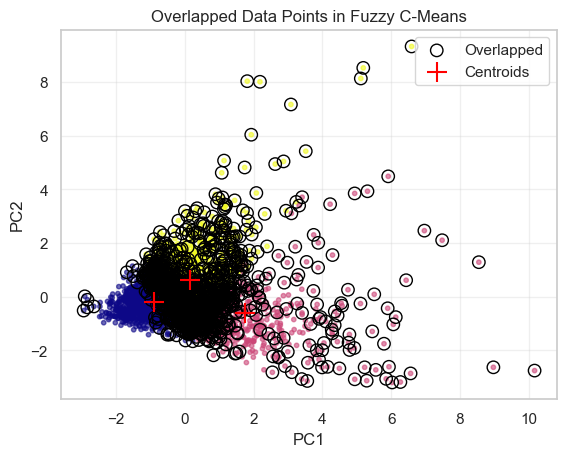

In [50]:
#Graphic Overlap
plt.scatter(X_pca2[:, 0], X_pca2[:, 1], c=np.argmax(u, axis=0), cmap = "plasma", s = 10, alpha = 0.6)
plt.scatter(overlap_points[:, 0], overlap_points[:, 1],
            edgecolors="black", facecolors="none", s=80, label="Overlapped")
plt.scatter(centroids_fcm[:, 0], centroids_fcm[:, 1], c="red", marker="+", s=200, label="Centroids")
plt.title("Overlapped Data Points in Fuzzy C-Means")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The graph shows the days classified as ambiguos by Fuzzy C-Means (black circles). Out of the total dataset of 1077 days.
As seen in the grapf these black circles are concentrated in the center and along the borderds between the clusters. It means that Identifying the overlapping days is higjly valuable for risk management.


### 4.4 Silhouette and Davies bouldin

#### K-Means

In [51]:
#Testing K- MEANS
sil_score = silhouette_score(x, y_kmeans)
db_score = davies_bouldin_score(x, y_kmeans)
print(f'Silhouette Score(n = 3):{sil_score}')
print(f'Davies_bouldin_score(n = 3): {db_score}')

Silhouette Score(n = 3):0.3611414718175844
Davies_bouldin_score(n = 3): 1.2118072503610027


#### FUZZY c-Means

In [52]:
#Testing FUZZY C-MEANS
fcm_labels = np.argmax(u, axis=0)
sil_fcm = silhouette_score(x, fcm_labels)
db_fcm = davies_bouldin_score(x, fcm_labels)

print(f" Silhouette Score: {sil_fcm:.4f}")
print(f" davies_bouldin Score: {db_fcm:.4f}")
print(f" FPC (Fuzzy Partition Coefficient): {fpc:.4f}")

 Silhouette Score: 0.2715
 davies_bouldin Score: 1.3504
 FPC (Fuzzy Partition Coefficient): 0.5136


### 4.5 comparation and interpretation of clusters

Interpertation of the 3 (K means):

- Cluster 1 (Normal): Regular trading days.
- Cluster 2 (High Volatility): Represent days with strong price movements and market stress.
- Cluster 3 Represent extreme days driving by abnormal trading volume.

After applying the tests, Kmeans is the best model for classification, it has higher Silhouette Score (0.36) and lower Davies Bouldin Score (1.21), meaning it creates clusters that are more separated and compact, However, Fuzzy C-Means offers a more realistic view the FPC of 0.51 shows that the clusters are moderately fuzzy. This means the algorithmn captured the ambiguos nature of the market.

## 5. TIME SERIES-EDA

In [53]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  
from statsmodels.tsa.arima_model import ARIMA       # Older ARIMA implementation (deprecated in newer statsmodels versions)
import statsmodels.api as sm                        # Main statsmodels API (used for ARIMA, SARIMA, etc.)
import statsmodels.tsa.api as smtsa                 # Time series analysis tools (alternative access to ARIMA, seasonal models, etc.)
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller,kpss
from tqdm import tqdm_notebook
from itertools import product
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.metrics import median_absolute_error, mean_squared_log_error
import warnings
warnings.filterwarnings('ignore')

### 5.1 Time series visualization (Close)

Before plotting the price over time, I need to prepare the data and conver the 'Date' colum from string format that allows  underdtand chronological order.

In [54]:
#Creating a Dataframe
df_TS  = df_QQQ
df_TS['Date'] = pd.to_datetime(df_TS['Date'], '%Y-%m-%d')
# Attach your own 'Data' index to the dataframe
df_TS.index = df_TS['Date']
# Drop the 'Date' column from the dataframe
df_TS.drop('Date', axis = 1, inplace = True)

In [55]:
# Display first 10 records
df_TS.head(10)

,Adj Close,Close,High,Low,Open,Volume,Volatility,Log Return,Range pct,Log Volume,Volatility_20,Volume_MA20,Volume_Ratio,Log Return_scaled,Range pct_scaled,Log Volume_scaled,Volatility_20_scaled,Volume_MA20_scaled,Volume_Ratio_scaled
Date,,,,,,,,,,,,,,,,,,,
2016-11-07,108.729156,116.349998,116.470001,115.300003,115.489998,26591200,1.169998,0.023479,1.005585,7.424738,0.008386,22029925.0,1.207049,1.672735,-0.249124,-0.635908,-0.345748,-0.973722,0.701154
2016-11-08,109.439400,117.110001,117.639999,115.959999,116.230003,20777900,1.680000,0.006511,1.434549,7.317602,0.007952,21680100.0,0.958386,0.389614,0.167953,-1.012923,-0.403851,-0.989893,0.051835
2016-11-09,109.944046,117.650002,117.839996,115.599998,115.739998,70234400,2.239998,0.004601,1.903951,7.846550,0.008021,24478430.0,2.869236,0.245153,0.624348,0.848456,-0.394654,-0.860538,5.041519
2016-11-10,108.168465,115.750000,118.379997,114.199997,118.220001,72825400,4.180000,-0.016282,3.611231,7.862283,0.008793,26978650.0,2.699372,-1.333938,2.284321,0.903821,-0.291333,-0.744963,4.597961
2016-11-11,108.215179,115.800003,116.050003,114.839996,115.250000,41115200,1.210007,0.000432,1.044911,7.614002,0.008787,27968745.0,1.470041,-0.070087,-0.210888,0.030117,-0.292172,-0.699195,1.387888
2016-11-14,107.121811,114.629997,115.940002,114.029999,115.830002,35906000,1.910004,-0.010155,1.666234,7.555167,0.009036,29054910.0,1.235798,-0.870648,0.393218,-0.176926,-0.258840,-0.648986,0.776224
2016-11-15,108.607643,116.220001,116.620003,115.330002,115.500000,31796600,1.290001,0.013775,1.109965,7.502381,0.009377,29680905.0,1.071281,0.938922,-0.147637,-0.362682,-0.213215,-0.620049,0.346632
2016-11-16,109.252495,116.910004,116.989998,115.669998,115.669998,16538100,1.320000,0.005920,1.129073,7.218486,0.009493,29822665.0,0.554548,0.344916,-0.129058,-1.361714,-0.197670,-0.613496,-1.002681
2016-11-17,110.046806,117.760002,117.779999,116.610001,116.849998,20598600,1.169998,0.007244,0.993545,7.313838,0.009642,29945985.0,0.687858,0.445053,-0.260831,-1.026168,-0.177700,-0.607796,-0.654576


I am chosing adj close because it represents the final referenced market price, and it is adjusted for dividends and stocks splits. This gives more realistic view of  the profitability . 

### 5.2 Trend, Seasonality and Anomalies 

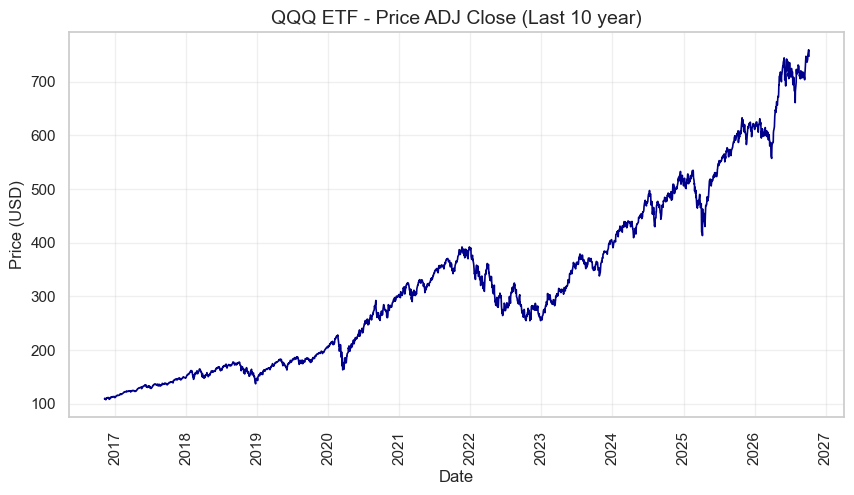

In [56]:
# Visualize the trend, seasonality and anomalies.
plt.figure(figsize=[10, 5]); # Set dimensions for figure
plt.plot(df_TS.index, df_TS['Adj Close'], 
          color = 'darkblue', linewidth=1.2)   
plt.title('QQQ ETF - Price ADJ Close (Last 10 year)', fontsize=14)
plt.ylabel('Price (USD)', fontsize=12)
plt.xlabel('Date', fontsize=12)
plt.xticks(rotation = 90)
plt.grid(alpha=0.3)
plt.show()

Trend: The graphic reveals a clear bullish trend with some notable anomalies: Market crashed due to the pandemic(2020) and market corrections in 2022. The events, are real historical events are not data errors.
Time Series Property: The variance is not constant and the data is non stationaty over time.Theredore, it will require a differencing process(d) for the ARIMA model.

### 5.3 Decomposition

Decomposition provides a useful abstract model for thinking about time series generally and for better understanding problems during time series analysis and forecasting. (Brownlee, 2017), to have a better undertanding of the model I apply Decomposition wich split the data in three components: Trend, Seasonality, and residuals(noise)

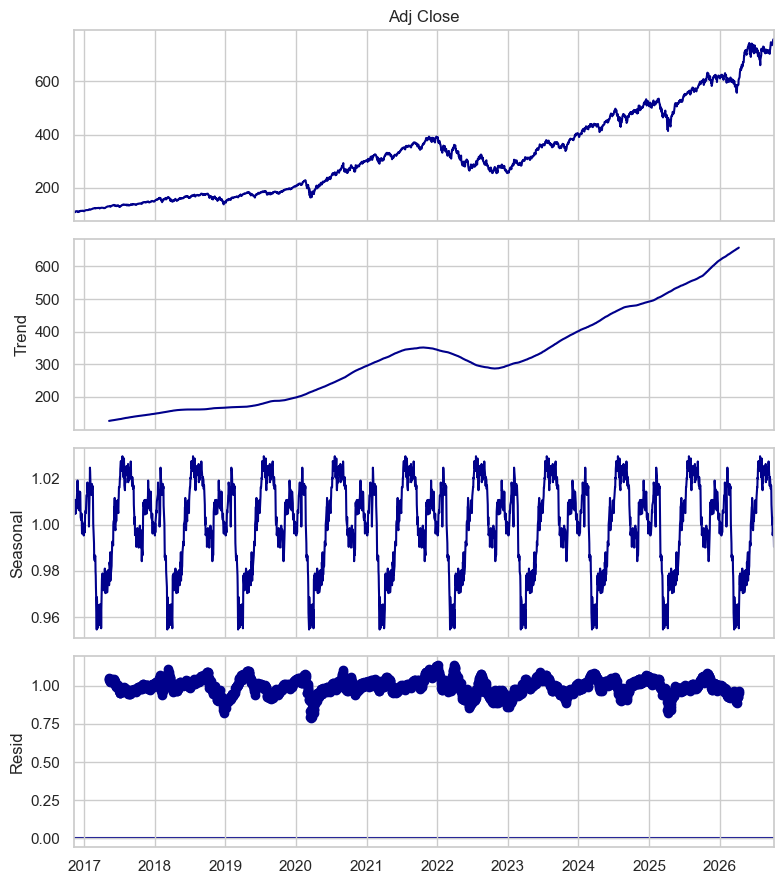

In [57]:
#Applying Decomposition 
decomposition = seasonal_decompose(df_TS['Adj Close'], model='multiplicative', period=252)
fig = decomposition.plot()
for graph in fig.axes:
    for line in graph.get_lines():
        line.set_color('darkblue')
fig.set_size_inches(8,9)
plt.tight_layout()
plt.show()

I selected the multiplicative model instead of the additive model, because the multiplicative model (Trend x Seasonality x Residuals) correctly captures the exponential growth beahviour, making it the most apropriate choice for stock market time series.

The graph is showing:
Trend: Shows the smooth, long term upward trjectory of the QQQ, GRWING FROM 150 usd TO 650 usd around in 10 years.
seasonal: The wave pattern reveals the annual cyclical behavior bases 252, it is not stacionary. 
Resid:The remaining noise is centered around 1.0. represent unpredictable market shocks (like Covid and inflation)


### 5.4 Stationarity test (ADF, KPSS).

The mean change with the years. It means that the serie it is not stacionary for example  in 2016, the price was 100 USD and in 2021 was 380 USD, the statistical models as Arima can not work with non stacionarian series because the mathimathics rules  asume that the serie is stable , that is why  we should flatten the serie, To make sure that the serie is stacionarian we use two test:

1. ADF (Augmented Dickey-Fuller)

- (HO): Non-Stacionarian serie
- (H1): Stacionarian serie
- Rule: if p-value is x>0.05 is non stacionary, if x<0.05  is stacionary.


2.KPSS (Kwiatkowski-Phillips-Schimidt-Shin)

- (HO): Stacionarian serie
- (H1): Non Stacionarian serie
- Rule: if p-value is x>0.05 is stacionary, if x<0.05  is non stacionary.


In [58]:
#Appliying Stacionarity Test
def test_stationarity (timeseries,title):
    print (f"Stacionarity Test: {title}")
    # Test ADF
    ADF = adfuller(timeseries.dropna(), autolag='AIC')
    print(f" ADF Statistic: {ADF[0]: .2f}")
    print(f" ADF p-value: {ADF[1]: .2f}")
    if ADF[1] <= 0.05:
        print("ADF: Stationary Serie (Reject H0)")
    else:
        print("ADF: Non Stationary Serie (No Reject H0)")
    # Test KPSS
    KPSS = kpss(timeseries.dropna(), regression='c', nlags='auto')
    print(f" KPSS Statistic: {KPSS[0]: .2f}")
    print(f" KPSS p-value: {KPSS[1]: .2f}")
    if KPSS[1] <= 0.05:
        print("KPSS: Non Stationary Serie (Reject H0)")
    else:
        print ("KPSS: Stationary Serie (No Reject H0)")
    print("\n")
# Testing the original Serie
test_stationarity(df_TS['Adj Close'],"Original serie(Adj Close)")
# Testing Differentiated serie (d=1)
test_stationarity(df_TS['Adj Close'].diff(),"Differentiated Serie(d=1)")

Stacionarity Test: Original serie(Adj Close)
 ADF Statistic:  1.24
 ADF p-value:  1.00
ADF: Non Stationary Serie (No Reject H0)
 KPSS Statistic:  7.23
 KPSS p-value:  0.01
KPSS: Non Stationary Serie (Reject H0)


Stacionarity Test: Differentiated Serie(d=1)
 ADF Statistic: -9.88
 ADF p-value:  0.00
ADF: Stationary Serie (Reject H0)
 KPSS Statistic:  0.29
 KPSS p-value:  0.10
KPSS: Stationary Serie (No Reject H0)




Before applying the Arima model, we tested the stationarity of the time series using two statistical test: ADF and KPSS:

1. Original serie (Adj Close):
   - ADF p-value:  1.00
   -  KPSS p-value:  0.01
Both test confirm that the original price series is non-stationary due to its strong long-term trend.

2. Differentiated Serie(d=1):
   - ADF p-value:  0.00
   - KPSS p-value:  0.10

After applting  applying a first order differencing (d=1), both test agree that the series becomes stationary.



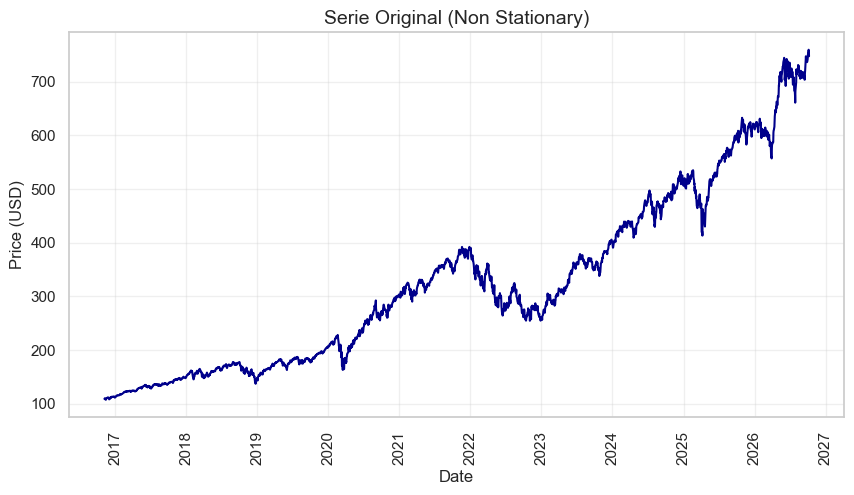

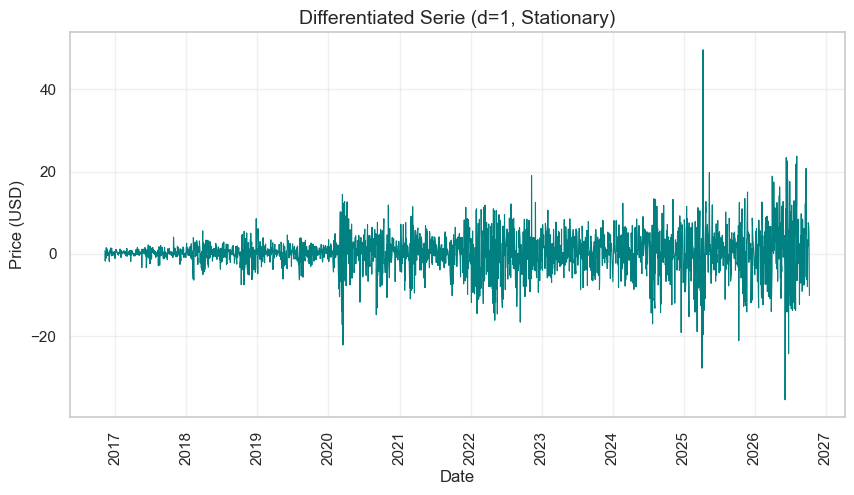

In [59]:
# Visualize  Original Serie
plt.subplots(figsize=(10, 5)) # Set dimensions for figure
plt.plot(df_TS.index, df_TS['Adj Close'], 
          color = 'darkblue')   
plt.title('Serie Original (Non Stationary)', fontsize=14)
plt.ylabel('Price (USD)', fontsize=12)
plt.xlabel('Date', fontsize=12)
plt.xticks(rotation = 90)
plt.grid(alpha=0.3)
plt.show()

# Visualize Differentiated Serie
plt.subplots(figsize=(10, 5)) # Set dimensions for figure
plt.plot(df_TS.index, df_TS['Adj Close'].diff(), 
          color = 'teal', linewidth=0.8)   
plt.title('Differentiated Serie (d=1, Stationary)', fontsize=14)
plt.ylabel('Price (USD)', fontsize=12)
plt.xlabel('Date', fontsize=12)
plt.xticks(rotation = 90)
plt.grid(alpha=0.3)
plt.show()

 The graphic is showing a original serie whit a general ascendet tendency it means that the median is not a constant, the second graph is representing a line wich is ocillates in a centered manner around of 0 value. The median is a constant.

To determine the d parameter of Arima model, I applied ADF and KPSS Test were applied. The original Adj Close  showed and ADF P-value of  1.00 and a KPSS P-value 0.01, confirming that the series is non-stationary. After I applied *(d=1)*, the test returned and ADF p-value of 0.00 and a KPSS p-value of 0.10, confirming that the differenced series became stationary.Therefore, the parameter d=1 is established for  the Arima model. I did not chose d=0 because it is applying for the original serie is stationary it is not our case and also if I applied  d=2 could lead ro over- differencing

### 5.5 ACF and PACF


We can use the statsmodels library to build auto-correlation (ACF) and partial auto-correlation plots from the differenced series. ACF describes how well the present value of the series is related with its past values while PACF finds correlation of the residuals with the next lag value.Iqbal, M. (2026)

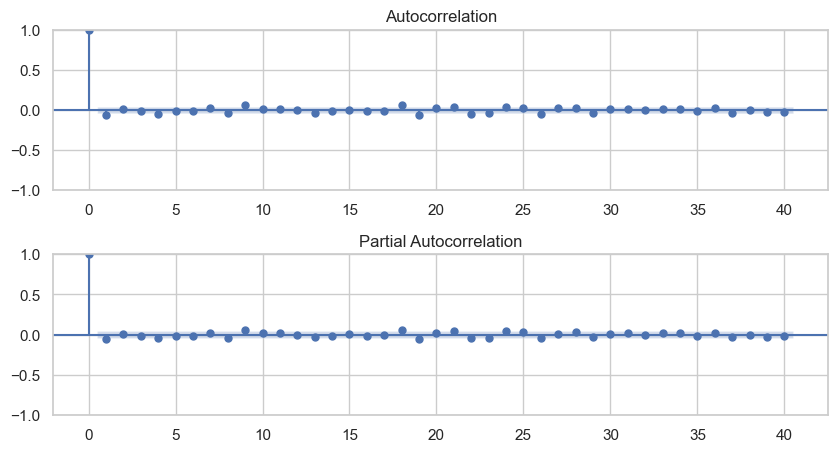

In [60]:
#Graphic ACF AND PACF
import statsmodels.api as sm
fig = plt.figure(figsize = (10, 5))
ax1 = fig.add_subplot(211)
fig = sm.graphics.tsa.plot_acf(df_TS['Adj Close'].diff().dropna(), lags = 40, ax = ax1)
ax2 = fig.add_subplot(212)
fig = sm.graphics.tsa.plot_pacf(df_TS['Adj Close'].diff().dropna(), lags = 40, ax = ax2)
plt.subplots_adjust(hspace=0.4)
plt.show()

In [61]:
#Applying ARIMA
from statsmodels.tsa.arima.model import ARIMA
candidates =[(0,1,0), (1,1,0), (0,1,1), (1,1,1), (2,1,0), (0,1,2)]
rows=[]
for order in candidates:
    adj =ARIMA (df_TS['Adj Close'], order=order).fit()
    rows.append({'order': order, 'AIC': adj.aic, 'BIC': adj.bic})
pd.DataFrame(rows).sort_values('AIC').round (1)

,order,AIC,BIC
1,"(1, 1, 0)",14975.9,14987.6
2,"(0, 1, 1)",14976.1,14987.7
3,"(1, 1, 1)",14977.7,14995.2
4,"(2, 1, 0)",14977.7,14995.2
5,"(0, 1, 2)",14977.8,14995.3
0,"(0, 1, 0)",14982.2,14988.1


In [62]:
#Verifying the parameters
train_size = int(len(df_TS)* 0.8)
train_data =df_TS['Adj Close'].values[:train_size]
test_data =df_TS['Adj Close'].values[train_size:]
m010 = ARIMA(train_data, order=(0,1,0)).fit()
m110 = ARIMA(train_data, order=(1,1,0)).fit()
for name, m in [('(0,1,0)', m010), ('(1,1,0)', m110)]:
    fc = m.forecast(steps=30)
    mae = mean_absolute_error(test_data[:30], fc)
    print(name, 'MAE:', round(mae, 2))


(0,1,0) MAE: 7.88
(1,1,0) MAE: 7.87


the graphs are showing:

1. Autocorrelation: Lag 0 = 1, it means today is 100% correlated with itself.
2. Partial Autocorrelation: since Lag1 (day1), everything fall down, all the points areinsede the blue area, it means that there is no statistically correlation with the precending days.

PACF and ACF

PACF (p): As the unique significative peak was Lag 0 is always 1.0 as it represents the correlation of the series with itself and the lag 1 it does not stand out the Autorregresive (AR)component it does not requires past days. Therefore p=0.

ACF (q): As the only significative peak was Lag 0 and the lag 1 is always 1.0 as it represents the correlation of the series with itself also it does not stand out it means the Moving Averahe (MA) component it does not requires past days. Therefore q=0.
    

### 5.6 Conclusions for selecting p,d, q.

In conclusion  for the Arima/Sarima I will use  as (pdq) = (0,1,0). The election of this model, It is stand up by the hyphotesis efficient Merch (Fama, 1995), where it says that the prices follow a random walk, therefore, past values do not contain predictive information about future process. Consequently an ARIMA (0,1,0) Is mathematicaly equivalent to a random walk (Duke University, 2007), was selecte. 

## 6 ARIMA/SARIMA

### ARIMA

### 6.1 Parameter determination
Following the conclusion from point 5.6, the selection of the Arima for the model were determined as follows:
p= 0 
d= 1 
q= 0
Therefore, the model to be implemented is an Arima(0,1,0)

### 6.2 Model fitting

The ARIMA (0,1,0) model is fitted using the adjusted close price of the QQQ ETF.

In [63]:
from statsmodels.tsa.arima.model import ARIMA

# Call ARIMA function to train the model on the 'Close' price
model = ARIMA(df_TS['Adj Close'].reset_index(drop=True),
              order = (0, 1, 0))

# Train ARIMA Model on the 'Adj Close' price dataset
results_AR = model.fit()

#Creating the column ARIMA with adjust values
df_TS['ARIMA'] = results_AR.fittedvalues.to_numpy ()

In [64]:
df_TS[['Adj Close', 'ARIMA']].head(10)

,Adj Close,ARIMA
Date,,
2016-11-07,108.729156,0.000000
2016-11-08,109.439400,108.729156
2016-11-09,109.944046,109.439400
2016-11-10,108.168465,109.944046
2016-11-11,108.215179,108.168465
2016-11-14,107.121811,108.215179
2016-11-15,108.607643,107.121811
2016-11-16,109.252495,108.607643
2016-11-17,110.046806,109.252495


In [65]:

arima_M = ARIMA(df_TS['Adj Close'].tolist(), order = (0, 1, 0))

# d = 1, the number of times that the raw observations are differenced, also called the degree of differencing.
# Train the ARIMA model by calling a method fit()
arima_M_fit = arima_M.fit()

# Display the summary of the trained model
arima_M_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                 2493
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -7490.120
Date:                Thu, 29 Oct 2026   AIC                          14982.239
Time:                        13:41:25   BIC                          14988.060
Sample:                             0   HQIC                         14984.353
                               - 2493                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2        23.8904      0.298     80.151      0.000      23.306      24.475
===================================================================================
Ljung-Box (L1) (Q):                   9.16   Jarque-Bera (JB):              7260.49
Prob(Q):                              0.00   Prob(JB):                         0.00
Heteroskedasticity (H):              13.76   Skew:                            -0.02
Prob(H) (two-sided):                  0.00   Kurtosis:                        11.36
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

* AIC: 14982.241
* BIC: 14988.061
* Hannan–Quinn: 14984.354
* Prob (JB): 0.00
* Prob (Q) : 0.00

The Arima (0,1,0) model was fited and its diagnostics were analyzed. The Aic value of 14982,241 serves as the baseline for model comparison. The residual diagnostics show a high kurtosis (11.04)and  a significant Jarque-Bera (JB) of 6714.89 (p-value ,0.05),indicating that residuals are not normally distributed

In [66]:
from sklearn.metrics import r2_score

# Drop NaNs and align properly
actual = df_TS['Adj Close'].iloc[1:]
predicted = df_TS['ARIMA'].iloc[1:]

r2 = r2_score(actual, predicted)
print(f"R² Score: {r2:.4f}")

R² Score: 0.9991


The model achieved and R2 of 0.9991, wich means it explains 99.91% of the variance. A high R2 confirms the model folloes  the trend .

In [67]:
print(results_AR.model.data.row_labels)
print(df_TS.index.freq)
print(type(df_TS.index))

RangeIndex(start=0, stop=2493, step=1)
None
<class 'pandas.core.indexes.datetimes.DatetimeIndex'>


In [68]:
# Forecast next 30 days
steps    = 30
#Results_AR, Obtain the model pronostic
result   = results_AR.get_forecast(steps=steps)
forecast = result.predicted_mean

print(forecast.head())

2493    747.580017
2494    747.580017
2495    747.580017
2496    747.580017
2497    747.580017
Name: predicted_mean, dtype: float64


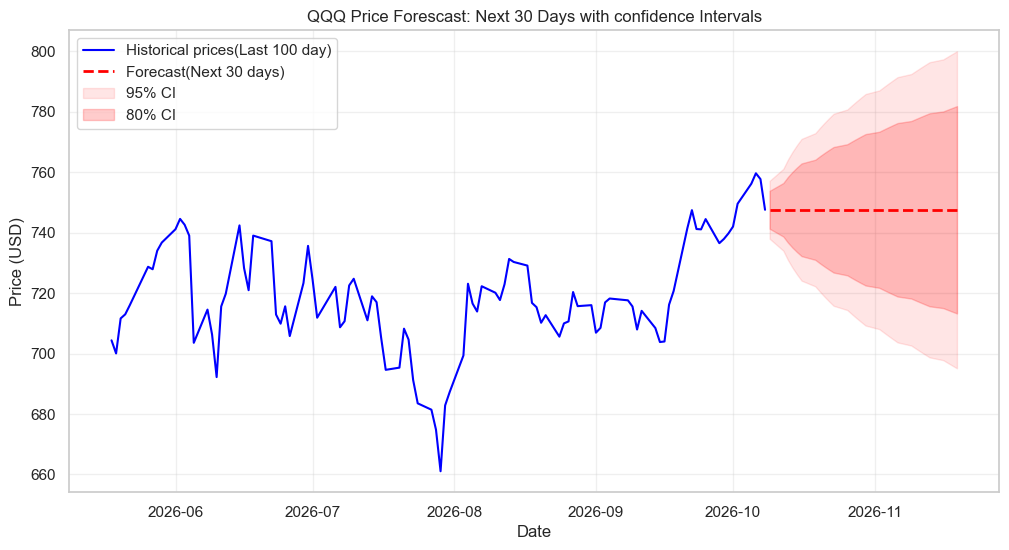

In [69]:

# Time indices
last_date = df_TS.index[-1]
future_dates = pd.date_range(start=last_date, periods=steps +1, freq='B')[1:]

# Get confidence intervals
ci_80 = result.conf_int(alpha = 0.20)   # 80% CI
ci_95 = result.conf_int(alpha = 0.05)   # 95% CI

lower_80 = ci_80.iloc[:, 0].values 
upper_80 = ci_80.iloc[:, 1].values
lower_95 = ci_95.iloc[:, 0].values
upper_95 = ci_95.iloc[:, 1].values
forecast_values = forecast.values

# Plot
plt.figure(figsize = (12, 6))

# Actual data
plt.plot(df_TS.index[-100:].values, df_TS['Adj Close'][-100:], label = "Historical prices(Last 100 day)", color='blue')

# Forecast
plt.plot(future_dates, forecast_values, color = "red", linestyle = "--", linewidth = 2, label = "Forecast(Next 30 days)")

# Confidence intervals
plt.fill_between(future_dates, lower_95, upper_95, alpha = 0.1, label = "95% CI", color='red')
plt.fill_between(future_dates, lower_80, upper_80, alpha = 0.2, label = "80% CI", color='red')

# Labels and title

plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.title("QQQ Price Forescast: Next 30 Days with confidence Intervals")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

The graph shows the forecast for the next 30 days based on the ARIMA (0,1,0) model with  a intervals of confidence of 80% and 95%:

- Historical prices(Blue Line): Shows the last 100 days of actual QQQ PRICES.
- Forecast (Red Line): The prediction is a flat line. This happens because ARIMA(0,1,0) is a Random walk model, it means the best prediction for tomoroww is today's price.
- Confidence intervals (Pink areas): The cone shape shows that uncertainly increases over time.


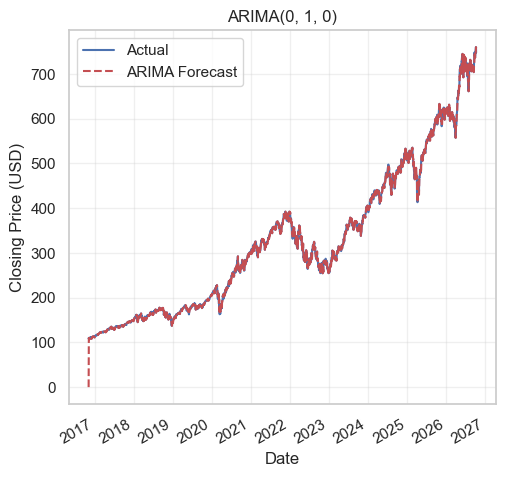

In [70]:
# Declare the objects f and array axarr
f, axarr = plt.subplots(1, sharex=True)
f.set_size_inches(5.5, 5.5)

# Ignore first two rows because of difference factor d = 2
df_TS['Adj Close'].plot(color='b', linestyle='-', ax=axarr, label='Actual')
df_TS['ARIMA'].plot(color='r', linestyle='--', ax=axarr, label='ARIMA Forecast')
axarr.set_title('ARIMA(0, 1, 0)')
axarr.set_xlabel('Date')
axarr.set_ylabel('Closing Price (USD)')
axarr.legend()  # Add legend

plt.grid(alpha=0.3)
plt.show()

The graph visually confirms that a Random walk model (0,1,0) is excellent at following historical trends, but as seen in the 30 day forecast graph, it cannot predict market direction.

#### SARIMA

In [71]:
sarima_model = SARIMAX(df_TS['Adj Close'], order=(0,1,0), seasonal_order=(1, 0, 0, 5)).fit(disp=False)

print(sarima_model.summary())
print('ARIMA AIC:', round(results_AR.aic, 1), '| SARIMA AIC:',round(sarima_model.aic,1))

                                     SARIMAX Results                                     
Dep. Variable:                         Adj Close   No. Observations:                 2493
Model:             SARIMAX(0, 1, 0)x(1, 0, 0, 5)   Log Likelihood               -7489.865
Date:                           Thu, 29 Oct 2026   AIC                          14983.730
Time:                                   13:41:26   BIC                          14995.372
Sample:                                        0   HQIC                         14987.957
                                          - 2493                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.S.L5       -0.0143      0.012     -1.166      0.243      -0.038       0.010
sigma2        23.8849      0.299     79.914

Sarima Extends ARIMA with a seasonal compnent an is only justidied when the seriw a showa a repeating pattern at a fixes interval. Before choosing the final model, seasionality was tested instead of  assumed: 
1. Visual evidence(ACF/PACF): After differencing (d=1), no lag falls outside  the 95% confidence band, so there is no autocorrelation estructure model.
2. Decomposition Limitation: The seasonal component in section 5.3 should not ne read as  evidence of seasonality.
3. Arima model achieved an AIC OF 14982.2,  Slightly lower than Sarima (0,1,0)(1,0,0,5) model, wich obtained an AIC OF 14983.7. It suggest that ARIMA provides a marginally better balance.

### 6.3 Forecasting evaluation (MAE,RMSE,MAPE).

In [73]:
df_TS = df_TS.sort_index()

all_prices = df_TS['Adj Close'].values

train_data = all_prices[:-30]
test_data = all_prices[-30:]

print(f"Size of train Data: {len(train_data)}")
print(f"Size of test Data: {len(test_data)}")


eval_model =ARIMA(train_data, order=(0,1,0))
eval_fit = eval_model.fit()

forecast_eval = eval_fit.forecast(steps = 30)

print(f"Size of Pronostic: {len(forecast_eval)}")

mae = mean_absolute_error(test_data, forecast_eval)
rmse = np.sqrt(mean_squared_error(test_data, forecast_eval))
mape = np.mean(np.abs((test_data -forecast_eval) / test_data)) *100

print(f"Pronostic Evaluation (last 30 days):")
print(f"MAE: {mae:.2f} USD")
print(f"RMSE: {rmse:.2f} USD")
print(f"MAPE: {mape:.2f}%")

Size of train Data: 2463
Size of test Data: 30
Size of Pronostic: 30
Pronostic Evaluation (last 30 days):
MAE: 19.44 USD
RMSE: 24.99 USD
MAPE: 2.62%


To evaluate the true predeictive power of ARIMA(0,1,0) model, the data was split chronologically: the model was trained on the  first 2463 days and tested on the last 30 days of real data. 
Pronostic Evaluation (last 30 days):
MAE: 19.44 USD the model's predictions deviate by an average of 19,44 USD from the real price.
RMSE: 24.99 USD this confirms the model does not make errors in its predictions
MAPE: 2.62% the model has an average percentage error of only 2,62% is considered highly accurate in financial forecasting (a MAPE below 5% is typically excellent).


### 6.4 Strengs and  limitations.

Strengths:

- Clear Market Segmentation.
- Detection of transition days.

Limitations:

- Inability to predict shocks.
- Fuzzy C-Means overlap.

## 7. Evaluation

### 7.1 Integration of clustering results and temporal series.

If the clustering model identifies that the market is entering a "High Volatility Regime" or shows many "Transition days", the investor can use this as a warning sign.  with this scenario, the ARIMA forecast should be interpreted with caution.

## 8. Conclutions

The main objective of this project was to segment QQQ tradaing days according to their behavior using unsupervised learnong and time series analysis, the following conclusions can be drawn:

1. Market Regimes Exist: I identified 3 distinct market regimes:
- Normal Regime: Low Volatility and average volume.
- High Volatility Regime: Large price movements and market stress.
- Volume Shock Regime: Extreme trading activity driven by news or panic moments.
2. Kmeans is the best model for strict Classification:Kmeans proved to be more effective than Fuzzy C means for clear segmentation with 0.36 and lower Davies Bouldin score 1.21.
3. Fuzzy C-Means: it reveals the market ambiguity. The market does not jump from calm to panic instantly: it has mixed behavior.
4. ARIMA provides Short Term Accuracy because it showed a hig accurate forecast a MAPE of 2,62%, however, the (0,1,0) a Random Walk  cannot predict sudden market shocks.

While it is impossible to predict the exact future price, undertanding the market regime and detecting transition days allws for smarter, data-driven risk management.

## 9. References

- @YahooFinance. (2019). NASDAQ Composite (^IXIC) Stock Price, Quote, History & News. [online] Available at: https://finance.yahoo.com/quote/%5EIXIC/ [Accessed 29 Sept. 2026].
- Ali, M. (2024). Agrupación en el aprendizaje automático: 5 Algoritmos de Agrupación Esenciales. [online] Datacamp.com. Available at: https://www.datacamp.com/es/blog/clustering-in-machine-learning-5-essential-clustering-algorithms [Accessed 3 Oct. 2026].
- Hayes, A. (2025). Volatility Definition. [online] Investopedia. Available at: https://www.investopedia.com/terms/v/volatility.asp [Accessed 6 Oct. 2026].
- Quantt (2026). ARIMA Model: Time Series Forecasting Explained 2026. [online] Quantt. Available at: https://www.quantt.co.uk/resources/arima-model-explained [Accessed 6 Oct. 2026].
[1] Rpubs.com. (2025). RPubs - Log Returns in Stock Market. [online] Available at: https://rpubs.com/sidewaysTimeTravel/1346935 [Accessed 6 Oct. 2026].
Ramuada, V.C. (2018). Forecasting Stock Returns: A Comparison of Five Models. [Academic thesis] Stellenbosch University. Available at:
- https://scholar.sun.ac.za/server/api/core/bitstreams/70ed3146-a1b2-475b-9519-232578edf560/content [Accessed 6 Oct. 2026].
Muller, D.S. (2023). Return Calculation. [online] EventStudy. Available at: https://eventstudy.de/docs/return-calculation [Accessed 6 Oct. 2026].
- https://www.utas.edu.au/__data/assets/pdf_file/0018/205182/03-2005_NJS-Error-Correction-Relationships-Between-High-Low-and-Consensus-Prices.pdf#3#1
sarged and Follow Following (2019). Logarithmic Volume — Indicator by sarged. [online] TradingView. Available at: https://www.tradingview.com/script/nJHera89-Logarithmic-Volume/ [Accessed 7 Oct. 2026].
- Goyenko, R.G., Bryan Kelly, Tobias Moskowitz, Yinan Su and Chao Zhang (2024). Trading Volume Alpha. McGill, Yale, AQR, and NBER.
Ajinkya, B.B. and Jain, P.C. (1989). The behavior of daily stock market trading volume. Journal of Accounting and Economics, [online] 11(4), pp.331–359. doi:10.1016/0165-4101(89)90018-9.
- BBVA (n.d.). ¿Qué son las inversiones financieras y qué tipos existen? [online] BBVA NOTICIAS. Available at: https://www.bbva.com/es/salud-financiera/que-son-las-inversiones-financieras-y-que-tipos-existen/ [Accessed 8 Oct. 2026].
- BBVA (n.d.). ¿Qué es el trading? ¿Qué hace falta para operar en los mercados? [online] BBVA NOTICIAS. Available at: https://www.bbva.com/es/salud-financiera/que-es-trading-que-hace-falta-para-operar/ [Accessed 8 Oct. 2026].
- Invesco. (2026). Invesco QQQ Trust, Series 1. [online] Available at: https://www.invesco.com/us/en/financial-products/etfs/invesco-qqq-trust-series-1.html [Accessed 8 Oct. 2026].
- Trevino, A. (2025). Introduction to K-means Clustering. [online] Oracle.com. Available at https://blogs.oracle.com/ai-and-datascience/introduction-to-k-means-clustering [Accessed 20 Oct. 2026].
- Brownlee, J. (2017). How to Decompose Time Series Data into Trend and Seasonality. [online] Machine Learning Mastery. Available at: https://machinelearningmastery.com/decompose-time-series-data-trend-seasonality/ [Accessed 21 Oct. 2026].
- Ullah, M.I. (2026). Mastering Time Series Differencing Explained Easy 2026. [online] Statistics for Data Analyst. Available at: https://itfeature.com/time-series/time-series-differencing/ [Accessed 22 Oct. 2026].
- Iqbal, M. (2026) 'Tutorial 6 (ARIMA and SARIMA)', MLBus_HDipData_Feb26_FT: Machine Learning for Business. Dublin: CCT College Dublin.
- Nau, R. (2007). Decision 411: Class 11. Available at: https://people.duke.edu/%7Ernau/Decision411_2007/411class11_2007_slides.pdf [Accessed 22 Oct. 2026].
- Fama, E.F. (1995). Random Walks in Stock Market Prices. Financial Analysts Journal, [online] 51(1), pp.75–80. doi:10.2469/faj.v51.n1.1861.
- Singh, A. (2024). The Impact of Investor’s Behavioural Factors on Investment Decisions in Financial Markets in Ireland. [online] Available at: https://esource.dbs.ie/server/api/core/bitstreams/6984a358-12d5-4396-b92e-4de6282f4cc2/content [Accessed 23 Oct. 2026].
- Invesco. (2025). Understanding QQQ’s performance through market cycles. [online] Available at: https://www.invesco.com/qqq-etf/en/innovation/understanding-qqqs-performance-through-market-cycles.html [Accessed 23 Oct. 2026].
- Abu Summaqa, Y. (2026). What is volatility in trading? volatility trading for beginners. [online] Equiti Default. Available at: https://www.equiti.com/sc-en/news/trading-ideas/what-is-volatility-in-trading-volatility-trading-for-beginners/ [Accessed 24 Oct. 2026].
- Volume ratio (VR) stock screener (no date) MarketInOut Stock Screener. Available at: https://www.marketinout.com/stock-screener/hub/vr (Accessed: 24 October 2026).
- Zhang, Y., Cucuringu, M., Shestopaloff, A.Y. and Zohren, S. (2026). ClusterLOB: enhancing trading strategies by clustering orders in limit order books. Quantitative Finance, 26(8), pp.1285–1309. doi:10.1080/14697688.2026.2665153.
-Zhang, L. (2026). Machine learning and game theory for cybercrime risk assessment in online platform management systems. Scientific Reports, [online] 16(1). doi:10.1038/s41598-026-46219-0.
-Aditi V (2024). Understanding Fuzzy C Means Clustering. [online] Analytics Vidhya. Available at: https://www.analyticsvidhya.com/blog/2024/05/understanding-fuzzy-c-means-clustering/ [Accessed 24 Oct. 2026].